# SupportBot — Modèle encodeur–décodeur (***Long Short-Term Memory***)

Ce notebook construit et entraîne le chatbot de service client. Il part des **paires nettoyées**
produites par le notebook `01_donnees.ipynb` (fichier `data/processed/paires_nettoyees.csv`) :
chaque paire associe le **message d'un client** (l'entrée du modèle) à la **réponse d'un agent**
(la sortie que le modèle apprend à générer).

**Plan du notebook :**

1. **Configuration** (graine aléatoire, processeur, nombre de paires) ;
2. **Chargement** des paires nettoyées et **échantillonnage** ;
3. **Découpage** en ensembles d'entraînement, de validation et de test ;
4. Construction du **vocabulaire** (avec les tokens spéciaux `<PAD>`, `<UNK>`, `<SOS>`, `<EOS>` et `<SEP>`) ;
5. **Représentation numérique** des textes (chaque token devient un numéro) ;
6. **Modèle 1** : encodeur–décodeur LSTM sans attention (modèle de référence) ;
7. **Entraînement** du modèle 1 ;
8. **Modèle 2** : ajout du mécanisme d'**attention** ;
9. **Génération** de réponses (greedy et beam search) ;
10. **Modèle 3** : ajout d'une **recherche TF-IDF** (RAG inspiré du raisonnement à partir de cas :
    CBR) : le modèle reçoit, en plus du message, la réponse d'un cas similaire ;
11. **Évaluation** et comparaison des trois modèles sur l'ensemble de test ;
12. **Exemples** de réponses réussies et d'échecs.
13. Synthèse des résultats.
14. Export des modèles pour l’application.



**Entraînement sur processeur (CPU).** L'ordinateur utilisé (Intel Core i7-1260P, 12 cœurs,
16 Go de mémoire) n'a pas de carte graphique NVIDIA : PyTorch effectue donc tous les calculs sur
le processeur. Pour que l'entraînement reste réalisable en quelques heures, le modèle est
volontairement **de taille modeste** (vocabulaire de 10 000 tokens, petites couches LSTM), et le
modèle est **sauvegardé à chaque epoch** pour pouvoir reprendre en cas d'interruption.

**Pourquoi 150 000 paires, et pas les 681 961 ?**

- **Le temps** : sur CPU, entraîner sur toutes les paires prendrait environ 4 à 5 fois plus
  longtemps, pour chacun des trois modèles ;
- **La quantité suffit** : 150 000 paires représentent déjà un volume important pour un modèle
  LSTM, et le dataset doit rester entraînable avec les ressources disponibles ;
- **La représentativité** : l'échantillon est tiré au hasard parmi toutes les paires ; il conserve
  donc la diversité des marques et des types de demandes.

Le code a d'abord été testé sur un petit échantillon de 5 000 paires, pour vérifier qu'il
fonctionne de bout en bout, puis exécuté sur 150 000 paires. Le nombre de paires est fixé par la
variable `N_PAIRES` dans la cellule de configuration. **Les résultats présentés dans ce notebook
sont ceux de l'entraînement sur 150 000 paires.**

## 1. Configuration

On fixe la **graine aléatoire** pour que les résultats soient reproductibles, on détecte l'appareil
disponible (ici le processeur) et on demande à PyTorch d'utiliser **tous les cœurs** du processeur
pour accélérer les calculs. On fixe enfin le nombre de paires utilisées pour l'entraînement.

In [45]:
import os
import random
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count())          # utiliser tous les cœurs du processeur
print(f"PyTorch {torch.__version__} | appareil utilisé : {device} | threads du CPU : {torch.get_num_threads()}")

N_PAIRES = 150_000                             # 5 000 pour tester le code, 150 000 pour l'entraînement final
print(f"Paires utilisées : {N_PAIRES:,}")

PyTorch 2.14.1+cpu | appareil utilisé : cpu | threads du CPU : 16
Paires utilisées : 150,000


**Interprétation :**

Aucune carte graphique NVIDIA n'est détectée : les calculs sont effectués sur le processeur (CPU),
en utilisant ses 16 threads. Le modèle est entraîné sur 150 000 paires tirées au hasard parmi les
681 961 paires nettoyées.

## 2. Chargement et échantillonnage

On charge les paires nettoyées, puis on tire un **échantillon aléatoire** : les 681 961 paires
disponibles dépassent largement ce qu'il est possible d'entraîner dans un temps raisonnable.

In [46]:
CHEMIN_PAIRES = "../data/processed/paires_nettoyees.csv"

toutes_les_paires = pd.read_csv(CHEMIN_PAIRES, keep_default_na=False)
print(f"Paires disponibles : {len(toutes_les_paires):,}")

paires = toutes_les_paires.sample(n=N_PAIRES, random_state=SEED).reset_index(drop=True)
del toutes_les_paires                          # on libère la mémoire : seul l'échantillon est utile
print(f"Échantillon        : {len(paires):,} paires")
paires.head(3)

Paires disponibles : 681,961
Échantillon        : 150,000 paires


,client_id,reponse_id,marque,message,reponse
0,2539096,2539094,sainsburys,go to to double up points for some christmas l...,"hi jordan , really sorry about that . which st..."
1,1159517,1159519,Delta,exit door release a little loose ? let's put a...,"josh , certainly understand the concern but be..."
2,2696076,2696075,AppleSupport,is anyone else's iphone doing that dumb shit w...,we'd like to help . dm us the ios version you'...


**Interprétation :**

Les 681 961 paires nettoyées sont chargées, puis un échantillon aléatoire de 150 000 paires est
tiré (graine 42, donc le même échantillon à chaque exécution). Les premières lignes montrent des
paires de marques différentes, signe que le tirage aléatoire mélange bien les données.

## 3. Découpage train / validation / test

On divise l'échantillon en trois ensembles :
- **entraînement (80 %)** : le modèle apprend sur ces paires ;
- **validation (10 %)** : on surveille l'apprentissage (surapprentissage) et on choisit le
  meilleur modèle ;
- **test (10 %)** : on évalue le modèle final, sur des paires qu'il n'a **jamais vues**.

L'échantillon ayant déjà été mélangé au hasard, il suffit de le découper dans l'ordre.

In [47]:
n_train = int(0.8 * len(paires))
n_val = int(0.1 * len(paires))

train = paires.iloc[:n_train].reset_index(drop=True)
val = paires.iloc[n_train:n_train + n_val].reset_index(drop=True)
test = paires.iloc[n_train + n_val:].reset_index(drop=True)

decoupage = pd.DataFrame({
    "Ensemble": ["Entraînement (train)", "Validation", "Test"],
    "Paires": [len(train), len(val), len(test)],
})
decoupage["% des paires"] = (decoupage["Paires"] / len(paires) * 100).round(1)
decoupage

,Ensemble,Paires,% des paires
0,Entraînement (train),120000,80.0
1,Validation,15000,10.0
2,Test,15000,10.0


**Interprétation :**

L'échantillon est découpé en 120 000 paires d'entraînement (80 %), 15 000 de validation (10 %)
et 15 000 de test (10 %). Les trois ensembles ne se chevauchent pas : les paires de test ne sont
jamais vues pendant l'entraînement, ce qui permet une évaluation honnête du modèle final.

## 4. Vocabulaire

Le modèle ne lit pas des mots mais des **numéros**. Le vocabulaire associe un numéro unique à
chaque token. Choix effectués :

- **Un vocabulaire commun** aux messages et aux réponses : les deux sont écrits dans la même
  langue (l'anglais du service client) et partagent la plupart de leurs mots. Ce choix est aussi
  nécessaire pour le modèle 3 (RAG), dont l'entrée contient à la fois un message et une réponse.
- **Cinq tokens spéciaux**, placés en tête du vocabulaire :

| Token | Numéro | Rôle |
|---|---|---|
| `<PAD>` | 0 | Remplissage, pour que toutes les séquences d'un paquet aient la même longueur |
| `<UNK>` | 1 | Remplace les mots absents du vocabulaire (mots inconnus) |
| `<SOS>` | 2 | Début de phrase : signal « commence à écrire » pour le décodeur |
| `<EOS>` | 3 | Fin de phrase : le décodeur s'arrête quand il le génère |
| `<SEP>` | 4 | Séparateur entre le message et la réponse du cas similaire (modèle 3, RAG) |

- **Seuls les mots fréquents** sont conservés : au maximum 10 000 tokens, apparaissant au moins
  3 fois. Les mots rares (fautes de frappe, noms propres peu fréquents) deviennent `<UNK>`. La taille du
  vocabulaire a un effet direct sur la vitesse : à chaque étape, le décodeur calcule une
  probabilité pour **chaque** token du vocabulaire. Une taille de 10 000 garde l'entraînement sur processeur réalisable, tout en couvrant la grande majorité des mots.
- **Le vocabulaire est construit uniquement sur l'ensemble d'entraînement.** S'il incluait la
  validation ou le test, le modèle « connaîtrait » déjà des mots qu'il n'est pas censé avoir vus,
  et son évaluation serait trop optimiste (data leakage : fuite de données).

Les tokens de la validation et du test absents du vocabulaire sont remplacés par `<UNK>`,
comme le seraient les mots nouveaux écrits par un vrai client.

*Les tokens `<url>` et `<num>`, créés lors du nettoyage, sont des tokens ordinaires : ils sont
assez fréquents pour entrer naturellement dans le vocabulaire.*

In [48]:
from collections import Counter

TOKENS_SPECIAUX = ["<PAD>", "<UNK>", "<SOS>", "<EOS>", "<SEP>"]
PAD, UNK, SOS, EOS, SEP = range(len(TOKENS_SPECIAUX))   # PAD = 0, UNK = 1, SOS = 2, EOS = 3, SEP = 4

TAILLE_MAX_VOCAB = 10_000
FREQ_MIN = 2 if N_PAIRES < 50_000 else 3      # petit échantillon de test : on garde les mots vus 2 fois

# Compter les tokens des messages ET des réponses de l'entraînement (uniquement)
compteur = Counter()
for texte in pd.concat([train["message"], train["reponse"]]):
    compteur.update(texte.split())
print(f"Tokens différents dans l'entraînement : {len(compteur):,}")

# Garder les plus fréquents
mots_gardes = [mot for mot, n in compteur.most_common(TAILLE_MAX_VOCAB - len(TOKENS_SPECIAUX))
               if n >= FREQ_MIN]

id2mot = TOKENS_SPECIAUX + mots_gardes                  # numéro -> mot
mot2id = {mot: i for i, mot in enumerate(id2mot)}       # mot -> numéro
TAILLE_VOCAB = len(id2mot)

print(f"Taille du vocabulaire : {TAILLE_VOCAB:,} tokens")
print("Les 15 premiers :", id2mot[:15])

Tokens différents dans l'entraînement : 68,420
Taille du vocabulaire : 10,000 tokens
Les 15 premiers : ['<PAD>', '<UNK>', '<SOS>', '<EOS>', '<SEP>', '.', 'to', 'the', ',', 'you', 'and', '?', 'a', 'i', 'for']


In [49]:
# Combien de tokens sont très rares ?
vus_une_fois = sum(1 for n in compteur.values() if n == 1)
vus_deux_fois = sum(1 for n in compteur.values() if n == 2)
print(f"Tokens vus une seule fois : {vus_une_fois:,} ({vus_une_fois / len(compteur):.0%})")
print(f"Tokens vus deux fois      : {vus_deux_fois:,} ({vus_deux_fois / len(compteur):.0%})")

Tokens vus une seule fois : 38,732 (57%)
Tokens vus deux fois      : 8,014 (12%)


**Interprétation :**

Les 120 000 paires d'entraînement contiennent **68 420 tokens différents**, mais la plupart sont
très rares : **38 732** (57 %) n'apparaissent qu'une seule fois et **8 014** (12 %) deux fois.
Ce sont surtout des fautes de frappe, des noms propres peu fréquents, des codes ou des mots
collés. C'est conforme à la loi de Zipf, selon laquelle quelques mots sont très fréquents et la
majorité très rares. Le vocabulaire garde les **10 000 tokens** les plus fréquents (dont les
5 tokens spéciaux), qui apparaissent tous au moins 3 fois : environ 85 % des tokens différents
sont donc exclus. Ces tokens exclus ne représentent pourtant qu'environ 2,2 % des occurrences de tokens dans les
messages et les réponses de l'entraînement (voir la couverture ci-dessous) : ils sont trop rares pour être appris, et les garder
multiplierait la taille de la couche de sortie, donc le temps d'entraînement. Les tokens les plus
fréquents sont la ponctuation et les mots-outils de l'anglais (« to », « the », « you »…).

In [50]:
def couverture(textes):
    """Pourcentage des tokens présents dans le vocabulaire."""
    tokens = [t for texte in textes for t in texte.split()]
    connus = sum(t in mot2id for t in tokens)
    return connus / len(tokens) * 100

resultats_vocab = pd.DataFrame({
    "Ensemble": ["Entraînement", "Validation", "Test"],
    "% de tokens connus": [round(couverture(pd.concat([d["message"], d["reponse"]])), 2)
                           for d in (train, val, test)],
})
resultats_vocab["% remplacés par <UNK>"] = (100 - resultats_vocab["% de tokens connus"]).round(2)
print(resultats_vocab)

print("\n=== Les 20 tokens les plus fréquents ===")
pd.DataFrame(compteur.most_common(20), columns=["token", "occurrences"])

       Ensemble  % de tokens connus  % remplacés par <UNK>
0  Entraînement               97.81                   2.19
1    Validation               97.70                   2.30
2          Test               97.71                   2.29

=== Les 20 tokens les plus fréquents ===


,token,occurrences
0,.,265693
1,to,165012
2,the,130588
3,",",119420
4,you,117486
5,and,86607
6,?,85311
7,a,84864
8,i,82237
9,for,76175


**Interprétation :**

Le vocabulaire couvre **97,81 %** des occurrences de tokens de l'entraînement : les tokens restants sont des mots
rares, absents du vocabulaire. Sur la validation et le test, la couverture est d'environ **97,7 %** :
les tokens non couverts seront remplacés par `<UNK>` (environ **2,3 %**), ce qui correspond à la situation réelle du
chatbot face à des messages nouveaux. La validation et le test ont une couverture presque
identique, signe que le découpage aléatoire produit des ensembles comparables. Parmi les tokens
les plus fréquents figurent la ponctuation, les mots-outils, `<url>`, ainsi que des mots typiques
du discours d'un agent (« you », « your », « we », « us », « can »).

On y retrouve aussi les deux voix de la conversation : « i » et « my » pour le client, « you »,
« your », « we » et « us » pour l'agent.

## 5. Représentation numérique

On transforme chaque texte en une séquence de numéros de longueur fixe :

- **Message (entrée de l'encodeur)** : chaque token est remplacé par son numéro (`<UNK>` s'il est
  absent du vocabulaire), la séquence est tronquée à **43 tokens** puis complétée avec `<PAD>`.
- **Réponse (sortie du décodeur)** : on ajoute `<SOS>` au début et `<EOS>` à la fin, puis on
  tronque à **39 tokens** et on complète avec `<PAD>`, soit une longueur totale de 41.
  `<SOS>` indique au décodeur où commencer, `<EOS>` lui apprend où s'arrêter.

Les longueurs maximales (43 et 39) correspondent au 95ᵉ percentile mesuré dans le notebook
`01_donnees.ipynb`.

Exemple :
```
Message : my order is late !     →  [14, 27, 9, 85, 21, 0, 0, …]          (43 numéros)
Réponse : sorry , please dm us   →  [2, 112, 8, 40, 61, 98, 3, 0, 0, …]  (41 numéros)
                                     ↑                       ↑
                                   <SOS>                   <EOS>
```

In [51]:
MAX_LEN_MESSAGE = 43    # 95e percentile des messages (notebook 01_donnees)
MAX_LEN_REPONSE = 39    # 95e percentile des réponses (notebook 01_donnees)

def texte_vers_ids(texte):
    """Remplace chaque token par son numéro (<UNK> s'il est inconnu)."""
    return [mot2id.get(token, UNK) for token in texte.split()]

def encoder_message(texte):
    """Message -> numéros, tronqué puis complété avec <PAD> (longueur 43)."""
    ids = texte_vers_ids(texte)[:MAX_LEN_MESSAGE]
    return ids + [PAD] * (MAX_LEN_MESSAGE - len(ids))

def encoder_reponse(texte):
    """Réponse -> <SOS> + numéros + <EOS>, complétée avec <PAD> (longueur 39 + 2 = 41)."""
    ids = [SOS] + texte_vers_ids(texte)[:MAX_LEN_REPONSE] + [EOS]
    return ids + [PAD] * (MAX_LEN_REPONSE + 2 - len(ids))

def ids_vers_texte(ids):
    """Numéros -> texte (s'arrête à <EOS>, ignore <PAD> et <SOS>)."""
    mots = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        mots.append(id2mot[i])
    return " ".join(mots)

exemple = train.iloc[0]
print("Message :", exemple["message"])
print("Numéros :", encoder_message(exemple["message"]))
print("Retour  :", ids_vers_texte(encoder_message(exemple["message"])))
print("\nRéponse :", exemple["reponse"])
print("Numéros :", encoder_reponse(exemple["reponse"]))
print("Retour  :", ids_vers_texte(encoder_reponse(exemple["reponse"])))

Message : go to to double up points for some christmas lights . ask staff where to go to do it . told can't today as no staff on customer service . yet 3 members of staff stood around talking . there's a reason i normally use and
Numéros : [144, 6, 6, 992, 62, 654, 14, 127, 478, 2366, 5, 467, 384, 214, 6, 144, 6, 51, 29, 5, 369, 114, 121, 69, 55, 384, 22, 119, 60, 5, 237, 172, 1171, 30, 384, 4245, 477, 1563, 5, 391, 12, 453, 13]
Retour  : go to to double up points for some christmas lights . ask staff where to go to do it . told can't today as no staff on customer service . yet 3 members of staff stood around talking . there's a reason i

Réponse : hi jordan , really sorry about that . which store did you visit ? mariya
Numéros : [2, 33, 2180, 8, 166, 39, 59, 35, 5, 120, 122, 153, 9, 388, 11, 2871, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Retour  : hi jordan , really sorry about that . which store did you visit ? mariya


**Interprétation :**

Le message est converti en 43 numéros : s'il est plus court, il est complété par des `<PAD>` (0) ;
s'il est plus long, il est tronqué, et seul son début (qui décrit généralement le problème du
client) est conservé. La réponse commence par `<SOS>` (2), se termine par `<EOS>` (3) et est
complétée par des `<PAD>` jusqu'à 41 numéros. La conversion inverse redonne le texte d'origine, à
l'exception des mots rares, qui deviennent `<UNK>`.

Certaines marques signent leurs réponses avec un prénom seul, sans symbole (par exemple
« mariya » chez Sainsbury's). Le nettoyage ne peut pas distinguer ces prénoms d'un mot ordinaire :
ils constituent une limite du nettoyage.

In [52]:
from torch.utils.data import TensorDataset, DataLoader

def vers_tenseurs(df):
    """Transforme les messages et les réponses d'un ensemble en tenseurs PyTorch."""
    X = torch.tensor([encoder_message(t) for t in df["message"]], dtype=torch.long)
    Y = torch.tensor([encoder_reponse(t) for t in df["reponse"]], dtype=torch.long)
    return X, Y

X_train, Y_train = vers_tenseurs(train)
X_val, Y_val = vers_tenseurs(val)
X_test, Y_test = vers_tenseurs(test)
print(f"Entraînement : messages {tuple(X_train.shape)} | réponses {tuple(Y_train.shape)}")
print(f"Validation   : messages {tuple(X_val.shape)} | réponses {tuple(Y_val.shape)}")
print(f"Test         : messages {tuple(X_test.shape)} | réponses {tuple(Y_test.shape)}")

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=BATCH_SIZE)

X_batch, Y_batch = next(iter(train_loader))
print(f"\nUn paquet : messages {tuple(X_batch.shape)} | réponses {tuple(Y_batch.shape)}")
print(f"Nombre de paquets par epoch : {len(train_loader)}")

Entraînement : messages (120000, 43) | réponses (120000, 41)
Validation   : messages (15000, 43) | réponses (15000, 41)
Test         : messages (15000, 43) | réponses (15000, 41)

Un paquet : messages (64, 43) | réponses (64, 41)
Nombre de paquets par epoch : 1875


**Interprétation :**

Les paires sont converties en tenseurs : l'ensemble d'entraînement devient une matrice de
120 000 × 43 numéros pour les messages et 120 000 × 41 pour les réponses. Les données
d'entraînement sont découpées en paquets de 64 paires, mélangés à chaque epoch, soit
1 875 paquets par epoch.

## 6. Modèle 1 : encodeur–décodeur LSTM (sans attention)

Le modèle de référence est composé de deux réseaux LSTM :

- **L'encodeur** lit le message du client token par token. Chaque numéro est d'abord transformé en
  un vecteur de 128 nombres (**embedding**), puis le LSTM met à jour sa mémoire à chaque token.
  À la fin du message, sa mémoire (l'**état caché** `h` et l'**état de cellule** `c`, de taille
  256) résume tout le message.
- **Le décodeur** reçoit ce résumé comme mémoire de départ, puis génère la réponse token par
  token : à chaque étape, une couche linéaire calcule un score pour chacun des tokens du vocabulaire ; pendant l’entraînement, ces scores sont comparés au vrai token suivant, et pendant la génération, le token le plus probable est choisi.

Choix effectués :

| Paramètre | Valeur | Raison |
|---|---|---|
| Taille des embeddings | 128 | Suffisant pour un vocabulaire de 10 000 tokens |
| Taille de la mémoire LSTM | 256 | Compromis entre capacité du modèle et temps d'entraînement sur CPU |
| Nombre de couches | 1 | Modèle de référence simple |
| Dropout | 0,3 | Désactive au hasard 30 % des valeurs pendant l'entraînement, pour limiter le surapprentissage |

Les `<PAD>` ajoutés à la fin des messages ne doivent pas modifier le résumé : l'encodeur
utilise `pack_padded_sequence`, qui indique au LSTM la vraie longueur de chaque message, pour
qu'il s'arrête au dernier vrai token.

In [53]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

TAILLE_EMBEDDING = 128
TAILLE_CACHEE = 256
DROPOUT = 0.3


class Encodeur(nn.Module):
    """Lit le message et le résume dans l'état caché (h, c) du LSTM."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)

    def forward(self, X):
        longueurs = (X != PAD).sum(dim=1).clamp(min=1).cpu()      # vraie longueur de chaque message
        emb = self.dropout(self.embedding(X))                     # (paquet, 43) -> (paquet, 43, 128)
        emb = pack_padded_sequence(emb, longueurs, batch_first=True, enforce_sorted=False)
        sorties, (h, c) = self.lstm(emb)                          # le LSTM ignore les <PAD>
        sorties, _ = pad_packed_sequence(sorties, batch_first=True, total_length=X.size(1))
        return sorties, (h, c)                                    # sorties : utiles pour l'attention (modèle 2)


class Decodeur(nn.Module):
    """Part du résumé (h, c) et calcule un score pour chaque token du vocabulaire."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)
        self.sortie = nn.Linear(taille_cachee, taille_vocab)

    def forward(self, Y_entree, etat):
        emb = self.dropout(self.embedding(Y_entree))              # (paquet, longueur, 128)
        sorties, etat = self.lstm(emb, etat)                      # (paquet, longueur, 256)
        scores = self.sortie(self.dropout(sorties))               # (paquet, longueur, taille du vocabulaire)
        return scores, etat


class Seq2Seq(nn.Module):
    """Encodeur + décodeur : le résumé du message sert de mémoire de départ au décodeur."""

    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, X, Y_entree):
        _, etat = self.encodeur(X)
        scores, _ = self.decodeur(Y_entree, etat)
        return scores

### 6.1 Vérification du modèle sur un paquet

On construit le modèle, on compte ses paramètres, puis on lui fait traiter un paquet pour vérifier
les dimensions. Pendant l'entraînement, le décodeur reçoit la réponse **décalée d'un cran**
(*teacher forcing*) : il reçoit `<SOS> sorry , please` et doit prédire `sorry , please <EOS>`.
À chaque position, il apprend donc à prédire le token suivant à partir des vrais tokens précédents.

In [54]:
modele1 = Seq2Seq(
    Encodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
    Decodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
).to(device)

nb_parametres = sum(p.numel() for p in modele1.parameters())
print(f"Nombre de paramètres : {nb_parametres:,}")

# Teacher forcing : entrée = réponse sans le dernier token, cible = réponse sans <SOS>
X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
Y_entree, Y_cible = Y_batch[:, :-1], Y_batch[:, 1:]
scores = modele1(X_batch, Y_entree)

print(f"Messages en entrée    : {tuple(X_batch.shape)}")
print(f"Entrée du décodeur    : {tuple(Y_entree.shape)}")
print(f"Scores en sortie      : {tuple(scores.shape)}")
print(f"Cible à prédire       : {tuple(Y_cible.shape)}")
print("\nExemple de décalage :")
print("Entrée :", [id2mot[i] for i in Y_entree[0, :6].tolist()])
print("Cible  :", [id2mot[i] for i in Y_cible[0, :6].tolist()])

Nombre de paramètres : 5,920,528
Messages en entrée    : (64, 43)
Entrée du décodeur    : (64, 40)
Scores en sortie      : (64, 40, 10000)
Cible à prédire       : (64, 40)

Exemple de décalage :
Entrée : ['<SOS>', 'sorry', 'to', 'hear', 'this', ',']
Cible  : ['sorry', 'to', 'hear', 'this', ',', 'our']


**Interprétation :**

Le modèle compte environ **5,9 millions de paramètres**, dont environ 87 % dépendent de la
taille du vocabulaire (les deux embeddings et la couche de sortie, qui calcule un score par
token). Le paquet traverse le modèle sans erreur : pour 64 messages de 43 tokens, le décodeur produit, à
chacune des 40 positions de la réponse, un score pour chaque token du vocabulaire. L'exemple montre
le décalage du *teacher forcing* : quand le décodeur reçoit `<SOS>`, il doit prédire le premier
mot ; quand il reçoit ce mot, il doit prédire le suivant, et ainsi de suite.

La stratégie utilisée est le teacher forcing complet (ratio = 1,0) : pendant l’entraînement, le décodeur reçoit toujours le vrai token précédent, jamais sa propre prédiction. Ce choix accélère et stabilise l’apprentissage, et permet de traiter toute la réponse en un seul passage du LSTM. 

## 7. Entraînement

À chaque paquet, le modèle prédit la réponse, on mesure son erreur, puis on corrige ses
paramètres :

- **La perte (loss)** est l'*entropie croisée*, calculée sur les $N$ positions qui ne sont pas des `<PAD>` (`ignore_index=PAD`) :
$$\mathcal{L} = -\frac{1}{N} \sum_{t=1}^{N} \log p\left(y_t \mid x, y_{<t}\right)$$
plus le modèle donne une probabilité faible au bon token $y_t$, plus la perte est élevée.
- **L'optimiseur Adam** (taux d'apprentissage 0,001) ajuste les paramètres pour réduire la perte.
- **Le gradient est limité** (*gradient clipping* à 1,0) : dans les LSTM, les corrections peuvent
  parfois devenir énormes et casser l'apprentissage ; on les plafonne.
- **La perplexité** est l'exponentielle de la perte, $\mathrm{PPL} = e^{\mathcal{L}}$ : elle s'interprète comme le nombre de tokens entre lesquels le modèle « hésite » en moyenne ; plus elle est basse, meilleur est le modèle.


Après chaque epoch, le modèle est évalué sur la validation. Deux sauvegardes sont faites :
le **meilleur modèle** (plus petite perte de validation), utilisé ensuite pour la génération, et
le **dernier état**, qui permet de reprendre l'entraînement s'il est interrompu.

In [55]:
import math
import time
import copy
from tqdm import tqdm

DOSSIER_CHECKPOINTS = "../checkpoints"
os.makedirs(DOSSIER_CHECKPOINTS, exist_ok=True)
N_EPOCHS = 10
critere = nn.CrossEntropyLoss(ignore_index=PAD)       # les <PAD> ne comptent pas dans l'erreur


def calculer_perte(modele, X, Y):
    """Perte du modèle sur un paquet (teacher forcing : la réponse est décalée d'un cran)."""
    X, Y = X.to(device), Y.to(device)
    Y_entree, Y_cible = Y[:, :-1], Y[:, 1:]
    scores = modele(X, Y_entree)
    return critere(scores.reshape(-1, scores.size(-1)), Y_cible.reshape(-1))


def passe(modele, loader, optimiseur=None):
    """Parcourt toutes les données : entraînement si un optimiseur est donné, sinon évaluation."""
    entrainement = optimiseur is not None
    modele.train(entrainement)                        # active le dropout seulement à l'entraînement
    perte_totale, nb_paquets = 0.0, 0
    with torch.set_grad_enabled(entrainement):
        for X, Y in tqdm(loader, leave=False):
            perte = calculer_perte(modele, X, Y)
            if entrainement:
                optimiseur.zero_grad()
                perte.backward()                      # calcul des corrections
                nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
                optimiseur.step()                     # application des corrections
            perte_totale += perte.item()
            nb_paquets += 1
    return perte_totale / nb_paquets


def entrainer(modele, nom, train=None, val=None, n_epochs=N_EPOCHS, lr=1e-3):
    """Entraîne le modèle, sauvegarde le meilleur et reprend si un entraînement a été interrompu."""
    train = train or train_loader                     # par défaut : les DataLoaders des messages
    val = val or val_loader
    chemin_meilleur = f"{DOSSIER_CHECKPOINTS}/{nom}_{N_PAIRES}_meilleur.pt"
    chemin_dernier = f"{DOSSIER_CHECKPOINTS}/{nom}_{N_PAIRES}_dernier.pt"
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []

    if os.path.exists(chemin_dernier):                # reprise après une interruption
        sauvegarde = torch.load(chemin_dernier, map_location=device)
        modele.load_state_dict(sauvegarde["modele"])
        optimiseur.load_state_dict(sauvegarde["optimiseur"])
        historique = sauvegarde["historique"]
        print(f"Sauvegarde trouvée : reprise après l'epoch {len(historique)}")

    meilleure_val = min((h["perte_val"] for h in historique), default=float("inf"))
    for epoch in range(len(historique) + 1, n_epochs + 1):
        debut = time.time()
        perte_train = passe(modele, train, optimiseur)
        perte_val = passe(modele, val)
        duree = (time.time() - debut) / 60
        historique.append({"epoch": epoch, "perte_train": perte_train,
                           "perte_val": perte_val, "duree_min": duree})

        meilleur = perte_val < meilleure_val
        if meilleur:
            meilleure_val = perte_val
            torch.save(modele.state_dict(), chemin_meilleur)
        torch.save({"modele": modele.state_dict(), "optimiseur": optimiseur.state_dict(),
                    "historique": historique}, chemin_dernier)
        print(f"Epoch {epoch:2d} | perte train {perte_train:.3f} | perte val {perte_val:.3f} "
              f"| perplexité val {math.exp(perte_val):6.1f} | {duree:.1f} min"
              + ("  ✓ meilleur" if meilleur else ""))

    modele.load_state_dict(torch.load(chemin_meilleur, map_location=device))   # on garde le meilleur
    return pd.DataFrame(historique)

### 7.1 Estimation du temps d'entraînement

Avant de lancer l'entraînement, on mesure le temps de traitement de 20 paquets (sur une copie du
modèle, pour ne pas modifier le vrai) et on en déduit la durée totale prévue.

In [56]:
def chronometrer(modele, train=None, n_paquets=20):
    """Temps moyen (en secondes) pour entraîner le modèle sur un paquet."""
    train = train or train_loader
    copie = copy.deepcopy(modele)
    optimiseur = torch.optim.Adam(copie.parameters(), lr=1e-3)
    copie.train()
    iterateur = iter(train)
    debut = time.time()
    for _ in range(n_paquets):
        X, Y = next(iterateur)
        perte = calculer_perte(copie, X, Y)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
    return (time.time() - debut) / n_paquets

secondes_par_paquet = chronometrer(modele1)
duree_prevue = secondes_par_paquet * len(train_loader) * N_EPOCHS / 60
print(f"Temps par paquet          : {secondes_par_paquet:.3f} s")
print(f"Paquets par epoch         : {len(train_loader):,}")
print(f"Durée prévue ({N_EPOCHS} epochs) : {duree_prevue:.0f} min ({duree_prevue / 60:.1f} h)")

Temps par paquet          : 0.741 s
Paquets par epoch         : 1,875
Durée prévue (10 epochs) : 232 min (3.9 h)


**Interprétation :**

L’entraînement d’un paquet de 64 paires prend environ 0,74 s sur le processeur. Avec 1 875 paquets par epoch et 10 epochs, l’entraînement du modèle 1 est estimé à environ 3,9 h, sans compter l’évaluation sur la validation après chaque epoch (plus rapide, car le modèle n’est pas corrigé). En pratique, la durée d’une epoch a varié de 12,5 à 24 minutes (voir la figure de la section 8.4), soit environ 3 heures au total. Cette durée reste compatible avec un entraînement sur CPU, ce qui confirme le choix d’un modèle de taille modeste.

### 7.2 Entraînement du modèle 1

L'entraînement a été interrompu après la première epoch, puis repris grâce à la sauvegarde du
dernier état : la fonction `entrainer` recharge le modèle, l'optimiseur et l'historique, puis
continue à l'epoch suivante. Lorsque les 10 epochs sont déjà terminées, elle recharge
directement le meilleur modèle sans le réentraîner. Le tableau ci-dessous présente le journal
complet des 10 epochs, conservé dans la sauvegarde.

In [57]:
historique1 = entrainer(modele1, "modele1")
# Journal complet de l'entraînement (relu depuis la sauvegarde)
historique1.assign(perplexite_val=np.exp(historique1["perte_val"])).round(3)

Sauvegarde trouvée : reprise après l'epoch 10


,epoch,perte_train,perte_val,duree_min,perplexite_val
0,1,3.968,3.258,22.430,25.996
1,2,3.228,2.979,20.309,19.671
2,3,3.077,2.840,23.810,17.122
3,4,2.957,2.757,16.822,15.759
4,5,2.877,2.699,12.771,14.864
5,6,2.815,2.658,12.507,14.265
6,7,2.769,2.620,14.863,13.739
7,8,2.730,2.596,16.407,13.408
8,9,2.696,2.576,17.013,13.150
9,10,2.669,2.554,16.457,12.859


**Interprétation :**

La perte d'entraînement et la perte de validation diminuent à chaque epoch : le modèle apprend
les régularités des réponses d'agents. La perplexité de validation passe de **26,0** après la
première epoch à **12,9** après la dixième : à la fin de l'entraînement, le modèle « hésite » en
moyenne entre environ 13 tokens à chaque position. La perte de validation reste inférieure à la perte d’entraînement, car le dropout n’est actif que pendant l’entraînement, et la perte d’entraînement est une moyenne calculée pendant l’epoch, alors que le modèle s’améliore encore. La perte de validation baissant à chaque epoch, il n’y a pas de surapprentissage. Le meilleur modèle (plus petite perte de validation, ici celui de la dernière
epoch) est conservé pour la génération.

La perte baisse encore légèrement à la dernière epoch (−0,02) : quelques epochs de plus apporteraient un petit gain. On est donc plutôt en léger sous-apprentissage qu’en surapprentissage.

## 8. Modèle 2 : encodeur–décodeur avec attention

Dans le modèle 1, tout le message est résumé dans un seul vecteur (l'état final de l'encodeur).
Pour un message long, ce résumé unique devient un **goulot d'étranglement** : des informations
sont perdues.

Le **mécanisme d'attention** (attention de Luong) lève cette limite : le décodeur garde accès aux
états de l'encodeur pour **chaque token** du message. À chaque étape de la génération :

1. l'état du décodeur est comparé à l'état de chaque token du message, ce qui donne un **score**
   par token ;
2. un *softmax* transforme ces scores en **poids d'attention** (positifs, des probabilités de somme 1) ; les
   positions `<PAD>` sont masquées et reçoivent un poids nul ;
3. le **vecteur de contexte** est la somme des états de l’encodeur, pondérée par ces poids ;
4. le contexte et l'état du décodeur sont combinés pour calculer le score de chaque token du
   vocabulaire.

L'encodeur est le même que celui du modèle 1 ; seul le décodeur change. Les poids d'attention
pourront être visualisés pour voir sur quels mots du message le modèle s'appuie pour écrire
chaque mot de sa réponse.

In [58]:
class Attention(nn.Module):
    """Attention de Luong : compare chaque état du décodeur à chaque état de l'encodeur."""

    def __init__(self, taille_cachee):
        super().__init__()
        self.W = nn.Linear(taille_cachee, taille_cachee, bias=False)

    def forward(self, etats_dec, sorties_enc, masque):
        # etats_dec : (paquet, Ly, 256) | sorties_enc : (paquet, Lx, 256) | masque : (paquet, Lx)
        scores = torch.bmm(etats_dec, self.W(sorties_enc).transpose(1, 2))   # (paquet, Ly, Lx)
        scores = scores.masked_fill(~masque.unsqueeze(1), float("-inf"))       # <PAD> : poids nul
        poids = torch.softmax(scores, dim=-1)                                  # pourcentages, somme = 1
        contexte = torch.bmm(poids, sorties_enc)                               # (paquet, Ly, 256)
        return contexte, poids


class DecodeurAttention(nn.Module):
    """Décodeur LSTM qui regarde les tokens du message à chaque étape."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)
        self.attention = Attention(taille_cachee)
        self.combinaison = nn.Linear(2 * taille_cachee, taille_cachee)
        self.sortie = nn.Linear(taille_cachee, taille_vocab)

    def forward(self, Y_entree, etat, sorties_enc, masque):
        emb = self.dropout(self.embedding(Y_entree))
        etats_dec, etat = self.lstm(emb, etat)                                 # (paquet, Ly, 256)
        contexte, poids = self.attention(etats_dec, sorties_enc, masque)
        combine = torch.tanh(self.combinaison(torch.cat([etats_dec, contexte], dim=-1)))
        scores = self.sortie(self.dropout(combine))                            # (paquet, Ly, vocabulaire)
        return scores, etat, poids


class Seq2SeqAttention(nn.Module):
    """Encodeur + décodeur avec attention."""

    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, X, Y_entree):
        sorties_enc, etat = self.encodeur(X)
        masque = X != PAD                                                      # True = vrai token
        masque[:, 0] = True                                                    # sécurité : jamais de ligne vide
        scores, _, _ = self.decodeur(Y_entree, etat, sorties_enc, masque)
        return scores

### 8.1 Vérification du modèle 2 sur un paquet

On construit le modèle, on compte ses paramètres, puis on vérifie sur un paquet les dimensions
des scores et des poids d'attention : pour chaque position de la réponse, les poids sur les
tokens du message doivent être positifs, nuls sur les `<PAD>`, et de somme 1.

In [59]:
modele2 = Seq2SeqAttention(
    Encodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
    DecodeurAttention(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
).to(device)

nb_parametres2 = sum(p.numel() for p in modele2.parameters())
print(f"Nombre de paramètres : {nb_parametres2:,} "
      f"(+{nb_parametres2 - nb_parametres:,} par rapport au modèle 1)")

# Vérification des poids d'attention sur un paquet
modele2.eval()
with torch.no_grad():
    sorties_enc, etat = modele2.encodeur(X_batch)
    masque = X_batch != PAD
    scores, _, poids = modele2.decodeur(Y_batch[:, :-1], etat, sorties_enc, masque)

print(f"Scores en sortie       : {tuple(scores.shape)}")
print(f"Poids d'attention      : {tuple(poids.shape)}  (paquet, positions de la réponse, tokens du message)")
print(f"Somme des poids        : {poids.sum(dim=-1).min():.4f} à {poids.sum(dim=-1).max():.4f}")
print(f"Poids sur les <PAD>    : {poids.masked_select(~masque.unsqueeze(1).expand_as(poids)).max():.4f}")

Nombre de paramètres : 6,117,392 (+196,864 par rapport au modèle 1)
Scores en sortie       : (64, 40, 10000)
Poids d'attention      : (64, 40, 43)  (paquet, positions de la réponse, tokens du message)
Somme des poids        : 1.0000 à 1.0000
Poids sur les <PAD>    : 0.0000


**Interprétation :**

L'attention n'ajoute qu'environ 197 000 paramètres (la matrice de comparaison et la couche de
combinaison), soit une augmentation d'environ 3 % par rapport au modèle 1. Les scores ont la même
forme que pour le modèle 1, ce qui permet de réutiliser les fonctions d'entraînement sans
modification. Les poids d'attention ont la forme attendue (un poids par token du message, pour
chaque position de la réponse) : ils sont de somme 1 et nuls sur les `<PAD>`, ce qui confirme que
le masque fonctionne.

### 8.2 Entraînement du modèle 2

On réutilise les mêmes fonctions que pour le modèle 1 : estimation du temps, puis entraînement
avec sauvegarde du meilleur modèle.

In [60]:
secondes_par_paquet2 = chronometrer(modele2)
duree_prevue2 = secondes_par_paquet2 * len(train_loader) * N_EPOCHS / 60
print(f"Temps par paquet          : {secondes_par_paquet2:.3f} s "
      f"(modèle 1 : {secondes_par_paquet:.3f} s)")
print(f"Durée prévue ({N_EPOCHS} epochs) : {duree_prevue2:.0f} min ({duree_prevue2 / 60:.1f} h)")

Temps par paquet          : 0.685 s (modèle 1 : 0.741 s)
Durée prévue (10 epochs) : 214 min (3.6 h)


In [61]:
historique2 = entrainer(modele2, "modele2")
# Journal complet de l'entraînement (relu depuis la sauvegarde)
historique2.assign(perplexite_val=np.exp(historique2["perte_val"])).round(3)

Sauvegarde trouvée : reprise après l'epoch 10


,epoch,perte_train,perte_val,duree_min,perplexite_val
0,1,3.977,3.103,16.223,22.258
1,2,3.097,2.815,13.092,16.690
2,3,2.904,2.700,16.086,14.873
3,4,2.799,2.625,19.881,13.808
4,5,2.728,2.574,12.504,13.120
5,6,2.675,2.538,12.949,12.652
6,7,2.631,2.509,13.021,12.295
7,8,2.596,2.486,12.755,12.014
8,9,2.566,2.470,12.757,11.825
9,10,2.540,2.450,12.568,11.594


**Interprétation :**

Le modèle 2 obtient une perte de validation plus basse que le modèle 1 dès la première epoch (perplexité 22,3 contre 26,0), et l’écart se maintient jusqu’à la fin de l’entraînement (perplexité 11,6 contre 12,9 pour le modèle 1). La perte de validation baisse à chaque epoch : il n’y a pas de surapprentissage. Le temps par paquet mesuré ici (0,685 s, contre 0,741 s pour le modèle 1) montre que l’attention ne ralentit presque pas l’entraînement : son coût est plus faible que les variations de vitesse de l’ordinateur d’une mesure à l’autre. La comparaison complète des deux modèles est faite sur l’ensemble de test, à la section 11.

### 8.3 Courbes d'apprentissage des modèles 1 et 2

On compare l'évolution de la perte d'entraînement et de validation des deux modèles. Si la perte
de validation remontait alors que la perte d'entraînement continue de baisser, ce serait un signe
de surapprentissage.

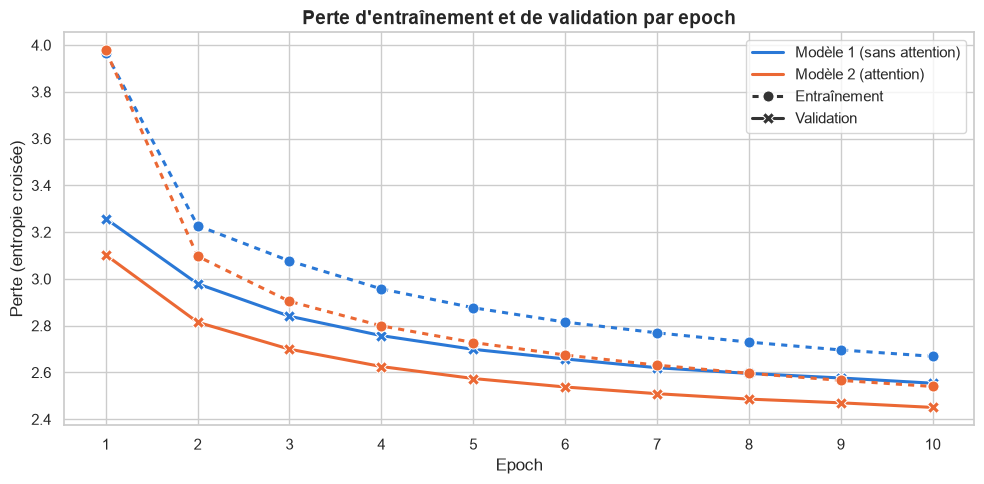

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
courbes = pd.concat([
    historique1.assign(modele="Modèle 1 (sans attention)"),
    historique2.assign(modele="Modèle 2 (attention)"),
]).melt(id_vars=["epoch", "modele"], value_vars=["perte_train", "perte_val"],
        var_name="ensemble", value_name="perte")
courbes["ensemble"] = courbes["ensemble"].map({"perte_train": "Entraînement", "perte_val": "Validation"})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=courbes, x="epoch", y="perte", hue="modele", style="ensemble",
             markers=True, dashes={"Entraînement": (2, 2), "Validation": ""},
             palette=["#2a78d6", "#eb6834"], linewidth=2.2, markersize=8, ax=ax)
ax.set_title("Perte d'entraînement et de validation par epoch", fontsize=14, weight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Perte (entropie croisée)")
ax.set_xticks(range(1, N_EPOCHS + 1))
poignees, etiquettes = ax.get_legend_handles_labels()
garder = [i for i, e in enumerate(etiquettes) if e not in ("modele", "ensemble")]
ax.legend([poignees[i] for i in garder], [etiquettes[i] for i in garder], title="")
plt.tight_layout()
plt.savefig("../reports/figures/courbes_modeles_1_2.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :**

Les quatre courbes diminuent régulièrement : les deux modèles apprennent de façon stable. La perte de validation ne remonte pas, ce qui indique l’absence de surapprentissage. Elle reste par ailleurs inférieure à la perte d’entraînement, car le dropout est actif pendant l’entraînement mais désactivé pendant l’évaluation. La courbe de validation du modèle 2 reste sous celle du modèle 1 à chaque epoch, avec un écart de 0,15 au début, qui se réduit légèrement à 0,10 en fin d’entraînement. Les courbes s’aplatissent en fin d’entraînement : quelques epochs supplémentaires n’apporteraient qu’un gain marginal.

### 8.4 Perplexité et durée des epochs

À gauche, la perplexité de validation (exponentielle de la perte) : le nombre moyen de tokens entre lesquels le modèle hésite. À droite, la durée de chaque epoch pour les deux modèles.

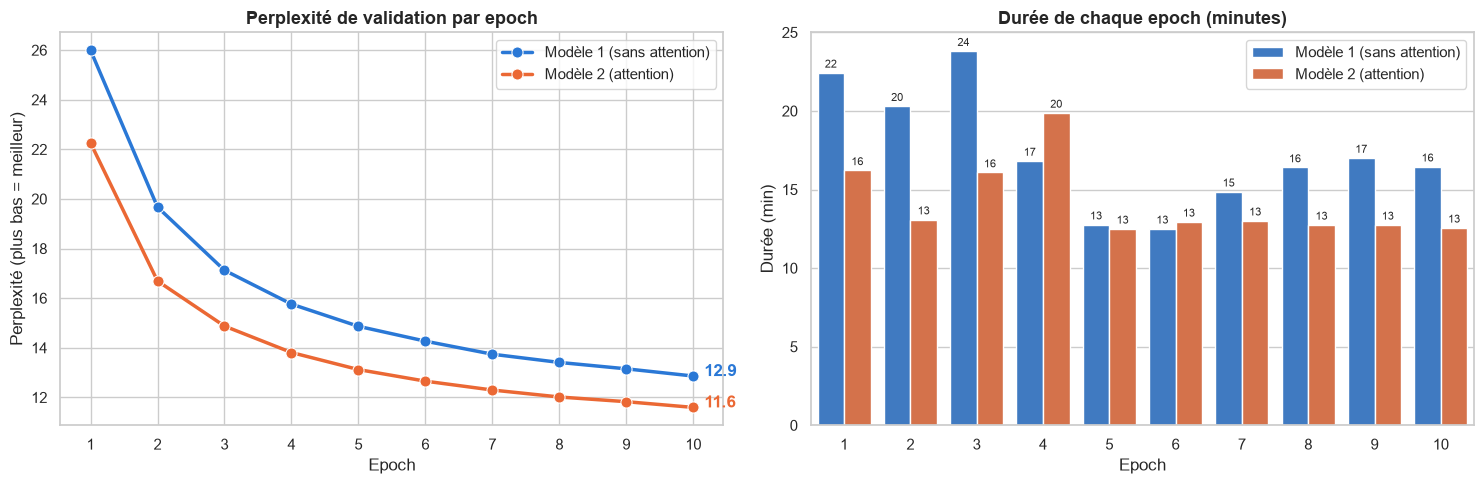

In [63]:
historiques = pd.concat([
    historique1.assign(modele="Modèle 1 (sans attention)"),
    historique2.assign(modele="Modèle 2 (attention)"),
])
historiques["perplexite_val"] = np.exp(historiques["perte_val"])
couleurs = {"Modèle 1 (sans attention)": "#2a78d6", "Modèle 2 (attention)": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Perplexité de validation
sns.lineplot(data=historiques, x="epoch", y="perplexite_val", hue="modele", palette=couleurs,
             marker="o", linewidth=2.5, markersize=8, ax=axes[0])
for modele, groupe in historiques.groupby("modele"):
    derniere = groupe.iloc[-1]
    axes[0].annotate(f"{derniere['perplexite_val']:.1f}", (derniere["epoch"], derniere["perplexite_val"]),
                     textcoords="offset points", xytext=(8, 0), color=couleurs[modele], weight="bold")
axes[0].set_title("Perplexité de validation par epoch", fontsize=13, weight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Perplexité (plus bas = meilleur)")
axes[0].set_xticks(range(1, N_EPOCHS + 1))
axes[0].legend(title="")

# Durée des epochs
sns.barplot(data=historiques, x="epoch", y="duree_min", hue="modele", palette=couleurs, ax=axes[1])
for conteneur in axes[1].containers:
    axes[1].bar_label(conteneur, fmt="%.0f", fontsize=8, padding=2)
axes[1].set_title("Durée de chaque epoch (minutes)", fontsize=13, weight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Durée (min)")
axes[1].legend(title="")

plt.tight_layout()
plt.savefig("../reports/figures/perplexite_et_duree.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :**

À gauche, la perplexité de validation du modèle 2 est plus basse que celle du modèle 1 à chaque epoch : elle passe de 22,3 à 11,6, contre 26,0 à 12,9 pour le modèle 1. La baisse est forte pendant les premières epochs, puis de plus en plus faible.

À droite, la durée des epochs varie de 12 à 24 minutes, selon l’utilisation de l’ordinateur pendant l’entraînement. Ces variations ne viennent pas de l’architecture : l’attention ne ralentit presque pas le calcul (section 8.2).

## 9. Génération de réponses

Pendant l'entraînement, le décodeur recevait la vraie réponse (*teacher forcing*). Pour générer
une réponse à un nouveau message, il écrit token par token, en recevant à chaque étape **le token
qu'il vient de générer**, jusqu'à produire `<EOS>` ou atteindre 39 tokens. Les tokens spéciaux
`<PAD>`, `<UNK>`, `<SOS>` et `<SEP>` sont interdits pendant la génération, pour que la réponse ne
contienne que de vrais mots.

Deux stratégies de choix du token suivant sont comparées :

- **Greedy search** : à chaque étape, le token le plus probable est choisi. Simple et rapide, mais
  un choix localement bon peut mener à une phrase globalement moins bonne.
- **Beam search** (largeur 5) : à chaque étape, les 5 débuts de phrase les plus probables sont
  conservés et prolongés ; à la fin, on garde la phrase complète la plus probable. Le score de
  chaque phrase est **normalisé par sa longueur**, sinon les phrases courtes seraient toujours
  favorisées (chaque token ajouté diminue la probabilité totale).

Pour le modèle 2, les **poids d'attention** sont conservés à chaque étape, pour être visualisés.

In [64]:
TOKENS_INTERDITS = [PAD, UNK, SOS, SEP]        # tokens que le modèle n'a pas le droit d'écrire


def preparer_message(modele, message, cas=None):
    """L'encodeur lit le message une seule fois (avec la réponse du cas similaire pour le modèle 3)."""
    ids = encoder_message(message) if cas is None else encoder_rag(message, cas)
    X = torch.tensor([ids], device=device)
    sorties_enc, etat = modele.encodeur(X)
    masque = X != PAD
    return sorties_enc, etat, masque


def etape_decodeur(modele, token, etat, sorties_enc, masque):
    """Un pas du décodeur : à partir du dernier token écrit, donne les scores du token suivant."""
    entree = torch.tensor([[token]], device=device)
    poids = None
    if isinstance(modele, Seq2SeqAttention):                       # modèle 2 : avec attention
        scores, etat, poids = modele.decodeur(entree, etat, sorties_enc, masque)
        poids = poids[0, -1]
    else:                                                          # modèle 1 : sans attention
        scores, etat = modele.decodeur(entree, etat)
    scores = scores[0, -1]
    scores[TOKENS_INTERDITS] = float("-inf")
    return scores, etat, poids


@torch.no_grad()
def generer_greedy(modele, message, cas=None):
    """Greedy : à chaque étape, on prend le token le plus probable."""
    modele.eval()
    sorties_enc, etat, masque = preparer_message(modele, message, cas)
    token, ids, attentions = SOS, [], []
    for _ in range(MAX_LEN_REPONSE):
        scores, etat, poids = etape_decodeur(modele, token, etat, sorties_enc, masque)
        token = scores.argmax().item()
        if token == EOS:                                           # le modèle a fini sa phrase
            break
        ids.append(token)
        attentions.append(poids)
    return ids_vers_texte(ids), ids, attentions


@torch.no_grad()
def generer_beam(modele, message, cas=None, largeur=5):
    """Beam search : on garde les `largeur` meilleurs débuts de phrase à chaque étape."""
    modele.eval()
    sorties_enc, etat, masque = preparer_message(modele, message, cas)
    faisceaux = [([SOS], 0.0, etat)]                               # (tokens, score, état)
    terminees = []

    for _ in range(MAX_LEN_REPONSE):
        # 1. Prolonger chaque début de phrase avec ses `largeur` meilleurs tokens
        candidats = []
        for tokens, score, etat in faisceaux:
            scores, nouvel_etat, _ = etape_decodeur(modele, tokens[-1], etat, sorties_enc, masque)
            log_probas = torch.log_softmax(scores, dim=-1)
            valeurs, indices = log_probas.topk(largeur)
            for log_p, token in zip(valeurs.tolist(), indices.tolist()):
                candidats.append((tokens + [token], score + log_p, nouvel_etat))

        # 2. Garder les `largeur` meilleurs candidats
        candidats = sorted(candidats, key=lambda c: c[1], reverse=True)[:largeur]

        # 3. Séparer les phrases terminées (<EOS>) de celles à prolonger
        faisceaux = []
        for candidat in candidats:
            if candidat[0][-1] == EOS:
                terminees.append(candidat)
            else:
                faisceaux.append(candidat)
        if not faisceaux:
            break

    # 4. Meilleure phrase, avec un score divisé par sa longueur
    meilleure = max(terminees + faisceaux, key=lambda c: c[1] / len(c[0]))
    return ids_vers_texte(meilleure[0])


### 9.1 Exemples de réponses générées

On compare, sur quelques messages de l'ensemble de **validation** (l'ensemble de test est réservé
à l'évaluation finale), la vraie réponse de l'agent et les réponses générées par les deux modèles, en greedy et en beam search, puis on teste quelques messages écrits à la main.

In [83]:
def comparer(message, reponse_reelle=None):
    """Affiche les réponses des modèles 1 et 2, en greedy et en beam search, pour un même message."""
    print(f"Message            : {message}")
    if reponse_reelle is not None:
        print(f"Vraie réponse      : {reponse_reelle}")
    print(f"Modèle 1 (greedy)  : {generer_greedy(modele1, message)[0]}")
    print(f"Modèle 1 (beam)    : {generer_beam(modele1, message)}")
    print(f"Modèle 2 (greedy)  : {generer_greedy(modele2, message)[0]}")
    print(f"Modèle 2 (beam)    : {generer_beam(modele2, message)}")
    print("-" * 100)

print("=== Messages de validation ===\n")
for _, ligne in val.sample(5, random_state=SEED).iterrows():
    comparer(ligne["message"], ligne["reponse"])

print("\n=== Messages écrits à la main ===\n")
messages_manuels = [
    "my order hasn't arrived yet and it's been two weeks !",
    "my iphone battery drains really fast since the last update",
    "i was charged twice for my subscription this month",
    "my flight was cancelled and nobody at the airport can help me",
]
for message in messages_manuels:
    comparer(message)

=== Messages de validation ===

Message            : well i updated my phone and now it just keeps turning on and off not doing anything and my phone provider say i need to drive towns over just to get it fixed . thanks
Vraie réponse      : we certainly want to make sure you've got a fully functional device , thompson . dm us so we can figure out a solution .
Modèle 1 (greedy)  : we'd like to help . please dm us your current ios version and we'll go from there . <url>
Modèle 1 (beam)    : thanks for reaching out to us . we'd like to look into this with you . send us a dm and we'll go from there . <url>
Modèle 2 (greedy)  : we'd like to help . which ios version are you using ?
Modèle 2 (beam)    : we'd like to look into this with you . send us a dm and we'll go from there . <url>
----------------------------------------------------------------------------------------------------
Message            : i'm trying to each customer service asap
Vraie réponse      : hello . is there anything 

**Interprétation :**

Les deux séries d’exemples sont complémentaires. Les messages de validation sont de vrais tweets de clients, tirés au hasard parmi des données qui n’ont jamais servi à entraîner le modèle (elles servent seulement à surveiller l’entraînement) : leur vraie réponse est connue, ce qui permet de comparer la réponse générée à celle d’un agent, sur des textes réels (fautes de frappe, argot, messages coupés). Les messages écrits à la main n’ont pas de vraie réponse : ils simulent l’utilisation de l’application par un client, avec des formulations claires choisies pour couvrir des problèmes différents (livraison, téléphone, facturation, voyage), et servent à vérifier si la réponse est adaptée au type de problème.


Les modèles ont appris à reconnaître le type d’entreprise et à reprendre son style, sans que le message la nomme toujours : ils demandent la version d’iOS pour un téléphone qui ne fonctionne plus après une mise à jour (Apple), un « idea number » et un « alternate number » pour un problème de données chez l’opérateur Idea (réponses très proches de la vraie réponse), un numéro de confirmation ou un « record locator » pour un vol annulé, ou un numéro de suivi pour une commande en retard. Le modèle 2 est souvent plus précis que le modèle 1 : il demande par exemple « email address and reservation code » pour un problème de réservation.

Le beam search ne donne pas toujours la meilleure réponse. Pour les deux messages sur un iPhone, les deux modèles demandent la version d’iOS en greedy, mais répondent en beam search par une formule générale (« send us a dm and we’ll go from there »). Le beam search choisit la phrase la plus probable dans son ensemble, ce qui favorise les formules les plus fréquentes dans les données : c’est cohérent avec la section 11, où il obtient un meilleur BLEU mais une diversité plus faible.

Plusieurs défauts apparaissent aussi : les modèles inventent parfois un prénom de client (« sarah ») et reproduisent des signatures d’agents (« neha l », « pritam », « vicky », « sj », « nq »), que le nettoyage n’a pas pu retirer. Ils reprennent aussi la formule d’une marque précise sans qu’elle soit nommée : pour un double prélèvement sur un abonnement, les quatre réponses utilisent la formule de Spotify (« we’ll take a look backstage »), la marque la plus fréquente pour ce sujet. Enfin, beaucoup de réponses reposent sur la même formule (« please dm us your email address »), ce qui reflète la fréquence de ces réponses types dans les données.

Le message sur le Redmi 4A montre une limite importante : la vraie réponse contient une information précise (ce téléphone n’est vendu qu’en vente flash), qu’aucun des deux modèles ne peut connaître ; les quatre réponses restent générales, et le modèle 1 en greedy demande même un numéro de suivi de commande, hors sujet. C’est la motivation du modèle 3 : retrouver un cas similaire dans les données d’entraînement et fournir sa réponse au modèle. De même, sur le vol annulé, le modèle 1 en greedy répond hors sujet (« we have been in touch »), alors que les trois autres réponses demandent une référence de réservation.

Ces exemples, peu nombreux, illustrent le comportement des modèles sans permettre de conclure : la comparaison chiffrée est faite à la section 11, sur l’ensemble de test (perplexité sur les 15 000 paires, BLEU et diversité sur 1 000 messages tirés au hasard).




### 9.2 Visualisation de l'attention

Pour un message donné, la carte ci-dessous montre, pour chaque token écrit par le modèle 2
(en lignes), le poids d'attention porté à chaque token du message (en colonnes). Plus la case est
foncée, plus le modèle s'appuie sur ce token du message pour écrire le token de la réponse.

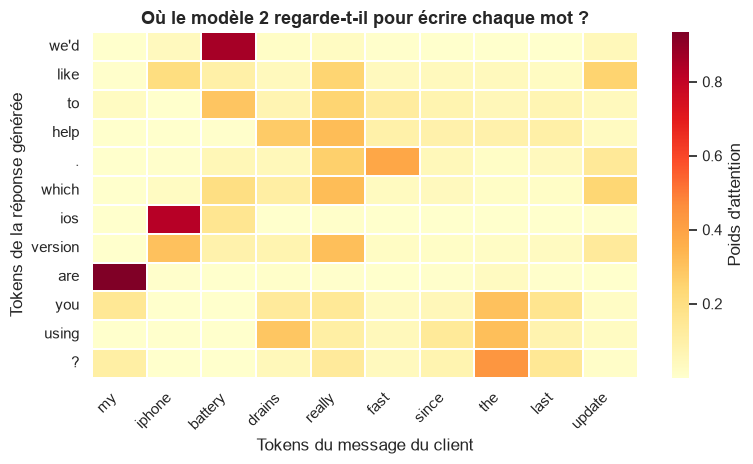

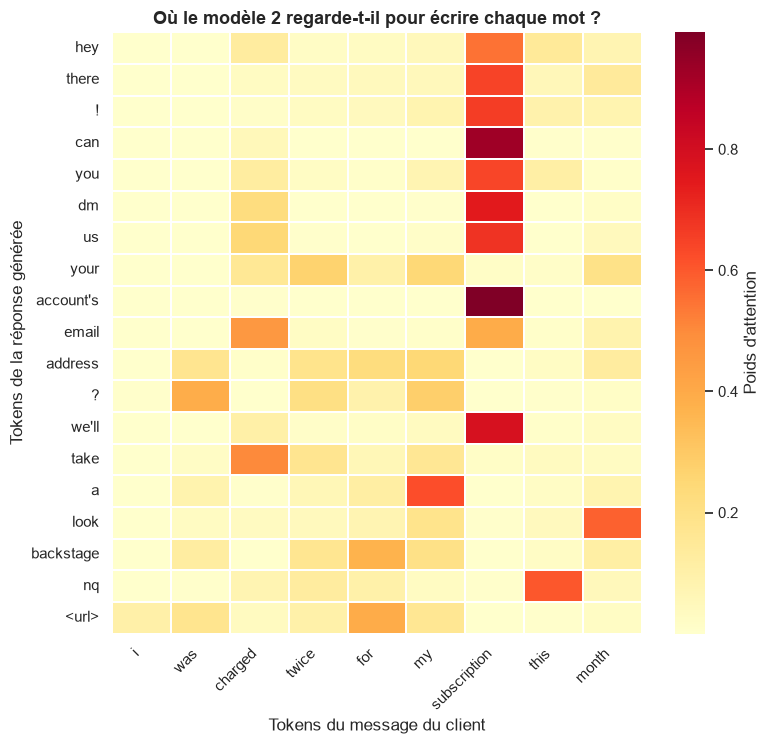

In [66]:
def afficher_attention(message, nom_fichier=None):
    """Carte des poids d'attention du modèle 2 pour un message."""
    texte, ids, attentions = generer_greedy(modele2, message)
    mots_message = [id2mot[i] for i in encoder_message(message) if i != PAD]
    mots_reponse = [id2mot[i] for i in ids]
    matrice = torch.stack(attentions)[:, :len(mots_message)].cpu().numpy()

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(mots_message)), max(4, 0.4 * len(mots_reponse))))
    sns.heatmap(matrice, xticklabels=mots_message, yticklabels=mots_reponse,
                cmap="YlOrRd", cbar_kws={"label": "Poids d'attention"}, linewidths=0.3, ax=ax)
    ax.set_xlabel("Tokens du message du client")
    ax.set_ylabel("Tokens de la réponse générée")
    ax.set_title("Où le modèle 2 regarde-t-il pour écrire chaque mot ?", fontsize=13, weight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    if nom_fichier:
        plt.savefig(f"../reports/figures/{nom_fichier}", dpi=150, bbox_inches="tight")
    plt.show()

afficher_attention("my iphone battery drains really fast since the last update",
                   "attention_iphone.png")
afficher_attention("i was charged twice for my subscription this month",
                   "attention_facturation.png")

**Interprétation :**

Les cartes montrent que l'attention a appris à s'appuyer sur les mots-clés du problème. Pour le
premier message, le modèle regarde presque uniquement « iphone » au moment d'écrire « ios » : il
a appris le lien entre l'appareil et son système d'exploitation. Pour le second, « subscription »
concentre l'attention pendant une grande partie de la réponse, en particulier pour écrire
« account's » : un abonnement est associé à un compte, que le modèle demande d'identifier.

Contrairement à la traduction, où l'attention aligne souvent les mots un à un, la réponse d'un
chatbot n'est pas une transformation mot à mot du message : l'attention se concentre plutôt sur
quelques mots porteurs du sujet, et certains poids sont plus difficiles à interpréter (par exemple
« are » qui regarde « my »). La seconde réponse reste par ailleurs générique : pour un double
prélèvement, un agent évoquerait plutôt un remboursement.

## 10. Modèle 3 : attention + recherche d'un cas similaire (RAG / CBR)

Les modèles 1 et 2 génèrent leurs réponses uniquement à partir de ce qu'ils ont mémorisé pendant
l'entraînement. Ils ne peuvent donc pas reproduire une information précise (un produit, une
procédure) qu'ils n'ont vue que rarement. Le modèle 3 s'inspire du **raisonnement à partir de cas**
(*case-based reasoning*), sur le principe du RAG (*retrieval-augmented generation*) :

1. **Recherche** : pour chaque message, on cherche dans l’ensemble d’entraînement le message le plus similaire adressé à la même marque, avec une représentation TF-IDF et la similarité cosinus, codées à la main ;
2. **Réutilisation** : la réponse de l'agent à ce message (le « cas similaire ») est ajoutée à
   l'entrée du modèle : `message <SEP> réponse du cas similaire` ;
3. **Adaptation** : le modèle avec attention (même architecture que le modèle 2) apprend à générer
   une réponse en s'appuyant à la fois sur le message et sur la réponse du cas similaire.

La mémoire des cas est uniquement l’ensemble d’entraînement : un message de validation ou de test ne peut jamais retrouver sa propre réponse. Pour les messages d’entraînement, le message lui-même est exclu de la recherche : chacun reçoit la réponse d’un autre message similaire, et doit apprendre à produire sa propre réponse en s’en inspirant. Sinon, le cas retrouvé serait la bonne réponse elle-même, et le modèle apprendrait simplement à la recopier, ce qui ne fonctionnerait plus sur de nouveaux messages. L’entraînement se fait ainsi dans les mêmes conditions que le test.


### 10.1 Représentation TF-IDF des messages

Chaque message est représenté par un vecteur de la taille du vocabulaire :

- **TF** (*term frequency*) : nombre d'occurrences du token dans le message, divisé par le nombre
  de tokens du message ;
- **IDF** (*inverse document frequency*) : log((1 + N) / (1 + df)) + 1, où N = 120 000 est le nombre de
  messages d'entraînement et df le nombre de messages contenant le token. Les tokens présents
  partout (« the », « . ») ont un IDF faible, les tokens rares et spécifiques (« refund »,
  « redmi ») un IDF élevé ;
- le vecteur est **normalisé** (norme 1) : la similarité cosinus entre deux messages est alors
  simplement le produit scalaire de leurs vecteurs.

Les vecteurs ne contiennent qu'une vingtaine de valeurs non nulles sur 10 000 : ils sont stockés
sous forme de **matrice creuse** (seules les valeurs non nulles sont gardées en mémoire).

In [67]:
# 1. IDF : dans combien de messages d'entraînement chaque token apparaît-il ?
N = len(train)
df = np.zeros(TAILLE_VOCAB)
for texte in train["message"]:
    for token in set(texte_vers_ids(texte)):
        df[token] += 1
idf = np.log((1 + N) / (1 + df)) + 1


# 2. TF-IDF d'un message : {token: poids}, avec une norme de 1
def vecteur_tfidf(texte):
    tokens = [t for t in texte_vers_ids(texte) if t != UNK]       # <UNK> ne compte pas
    poids = {t: n / len(tokens) * idf[t] for t, n in Counter(tokens).items()}   # TF × IDF
    norme = math.sqrt(sum(p ** 2 for p in poids.values()))
    return {t: p / norme for t, p in poids.items()}


# 3. Matrice creuse : une ligne par message, une colonne par token du vocabulaire
def matrice_tfidf(textes):
    lignes, colonnes, valeurs = [], [], []
    for i, texte in enumerate(textes):
        for token, poids in vecteur_tfidf(texte).items():
            lignes.append(i)
            colonnes.append(token)
            valeurs.append(poids)
    return torch.sparse_coo_tensor([lignes, colonnes], valeurs, (len(textes), TAILLE_VOCAB),
                                   dtype=torch.float32)


M_train = matrice_tfidf(train["message"])
print(f"Matrice TF-IDF de l'entraînement : {tuple(M_train.shape)}")
print(f"Valeurs non nulles par message   : {M_train._nnz() / N:.1f} en moyenne")

# L'IDF de quelques tokens : faible pour les mots fréquents, élevé pour les mots spécifiques
for mot in [".", "the", "order", "refund", "redmi"]:
    print(f"IDF de « {mot} » : {idf[mot2id[mot]]:.2f}")

Matrice TF-IDF de l'entraînement : (120000, 10000)
Valeurs non nulles par message   : 18.5 en moyenne
IDF de « . » : 1.61
IDF de « the » : 1.97
IDF de « order » : 4.36
IDF de « refund » : 5.18
IDF de « redmi » : 9.86


**Interprétation :**

La matrice TF-IDF des 120 000 messages d'entraînement ne contient en moyenne que 18,5 valeurs non
nulles par message, sur 10 000 colonnes : la stocker sous forme creuse évite de garder en mémoire
plus de 99 % de zéros. Les valeurs d'IDF illustrent le principe de la pondération : les tokens
présents dans presque tous les messages ont un poids faible (1,61 pour « . », 1,97 pour « the »),
tandis que les tokens spécifiques à un problème ont un poids élevé (4,36 pour « order », 5,18 pour
« refund », 9,86 pour « redmi »). La recherche de cas similaires s'appuie donc surtout sur les mots
qui décrivent le problème du client.

### 10.2 Recherche du cas le plus similaire

Pour chaque message, on calcule sa similarité cosinus avec les 120 000 messages d'entraînement,
et on garde le plus similaire parmi ceux adressés à la même marque : dans un vrai déploiement, on sait à quelle entreprise le client écrit, et un cas d’une autre entreprise n’aurait pas de sens. Le calcul est fait par paquets de 256 messages pour limiter la
mémoire utilisée.

In [68]:
# Chaque marque reçoit un numéro, pour comparer les marques rapidement
numeros_marques = {marque: i for i, marque in enumerate(train["marque"].unique())}
marques_train = torch.tensor(train["marque"].map(numeros_marques).values)


def rechercher(df, exclure_soi_meme=False):
    """Pour chaque message : le message d'entraînement de la même marque le plus similaire."""
    textes = list(df["message"])
    marques = torch.tensor(df["marque"].map(numeros_marques).fillna(-1).astype(int).values)
    indices, similarites = [], []
    for debut in tqdm(range(0, len(textes), 256)):                 # par paquets de 256 messages
        paquet = matrice_tfidf(textes[debut:debut + 256]).to_dense()
        sim = torch.sparse.mm(M_train, paquet.T)                    # similarités cosinus
        autre_marque = marques_train[:, None] != marques[None, debut:debut + 256]
        sim[autre_marque] = -1                                      # seulement la même marque
        if exclure_soi_meme:                                        # ne pas se retrouver soi-même
            j = torch.arange(len(paquet))
            sim[debut + j, j] = -1
        meilleure_sim, meilleur = sim.max(dim=0)
        indices += meilleur.tolist()
        similarites += meilleure_sim.tolist()
    return np.array(indices), np.array(similarites)


cas_train, sim_train = rechercher(train, exclure_soi_meme=True)
cas_val, sim_val = rechercher(val)
cas_test, sim_test = rechercher(test)

# Trois exemples sur la validation
for i in range(3):
    print(f"\n Message           : {val['message'][i]}  ({val['marque'][i]})")
    print(f"Message similaire : {train['message'][cas_val[i]]}  "
          f"({train['marque'][cas_val[i]]}, similarité {sim_val[i]:.2f})")
    print(f"Sa réponse        : {train['reponse'][cas_val[i]]}")
    print(f"Vraie réponse     : {val['reponse'][i]}")

100%|██████████| 59/59 [01:05<00:00,  1.12s/it]


💬 Message           : stop hikacking my account . i need to login . can't get sms . no other options provided . this is not acceptable !  (AskPayPal)
🔎 Message similaire : are you having trouble ? i can't get to the login page .  (AskPayPal, similarité 0.28)
📋 Sa réponse        : hi there ! we are sorry to hear about this . please send us a dm so we can assist you further ! looking forward to your response ! lar
✅ Vraie réponse     : hi there ! we are sorry to hear that you are having issues getting into your account . in order to better assist yo . <url>

💬 Message           : why your app freaking out so bad bud ?  (SpotifyCares)
🔎 Message similaire : fix your app  (SpotifyCares, similarité 0.25)
📋 Sa réponse        : hi nick ! what seems to be the issue ? can you let us know the device , os , and spotify version you're using ? we'll see what we can suggest ny
✅ Vraie réponse     : hey anika ! what exactly is going on with your spotify ? we'll do our best to help you out bh

💬 Messa


**Interprétation :**


Les cas retrouvés appartiennent bien à la même marque et traitent souvent du même type de problème : un problème d’accès au compte PayPal retrouve un autre problème de connexion, et un problème d’application Spotify retrouve une réponse qui demande l’appareil, le système et la version de l’application, exactement les informations utiles. Le troisième exemple montre en revanche qu’une similarité plus élevée (0,50) ne garantit pas un cas plus utile : les deux messages partagent surtout des mots de demande d’aide, et la réponse retrouvée (« please check your messages ») n’aide pas à résoudre le problème. La similarité TF-IDF mesure le recouvrement des mots, pas la pertinence du cas. Le modèle 3 bénéficie aussi d’une information que n’ont pas les modèles 1 et 2 : la marque à laquelle le client écrit.

### 10.3 Distribution des similarités

On observe à quel point les cas retrouvés sont proches des messages : une similarité proche de 1
signifie un message presque identique, une similarité proche de 0 un cas qui n'a presque aucun mot
important en commun.

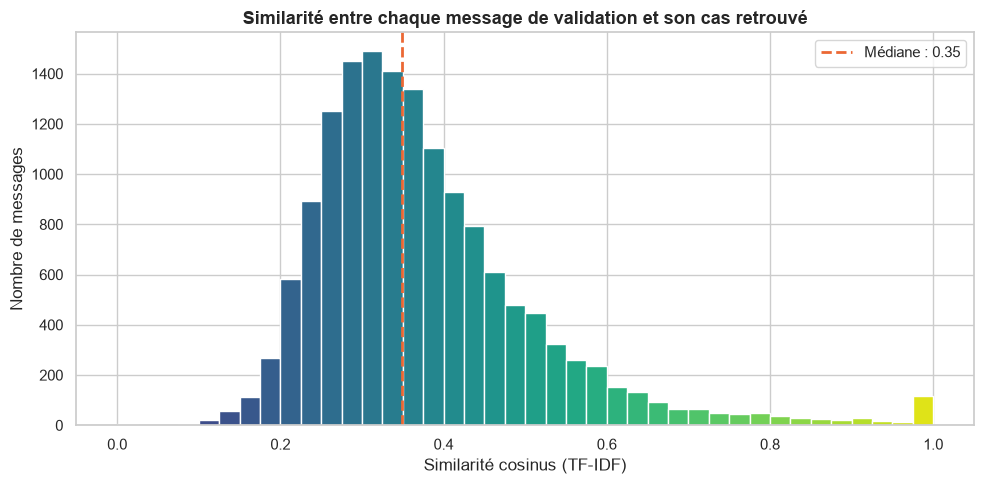

Similarité moyenne                     : 0.38
Cas très proche (similarité ≥ 0,8)     : 1.9%
Pas de cas vraiment proche (< 0,3)     : 31.0%


In [69]:
fig, ax = plt.subplots(figsize=(10, 5))
_, _, barres = ax.hist(sim_val, bins=40, edgecolor="white")
for barre, couleur in zip(barres, plt.cm.viridis(np.linspace(0.15, 0.95, len(barres)))):
    barre.set_facecolor(couleur)                                    # dégradé de couleurs
ax.axvline(np.median(sim_val), color="#eb6834", linestyle="--", linewidth=2,
           label=f"Médiane : {np.median(sim_val):.2f}")
ax.set_title("Similarité entre chaque message de validation et son cas retrouvé",
             fontsize=13, weight="bold")
ax.set_xlabel("Similarité cosinus (TF-IDF)")
ax.set_ylabel("Nombre de messages")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/similarites_rag.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Similarité moyenne                     : {sim_val.mean():.2f}")
print(f"Cas très proche (similarité ≥ 0,8)     : {(sim_val >= 0.8).mean():.1%}")
print(f"Pas de cas vraiment proche (< 0,3)     : {(sim_val < 0.3).mean():.1%}")

**Interprétation :**

La similarité entre un message et son cas retrouvé est le plus souvent modérée : médiane de 0,35
et moyenne de 0,38. Seuls 1,9 % des messages de validation ont un cas très proche (similarité
supérieure ou égale à 0,8), tandis que 31 % n'ont pas de cas vraiment proche (similarité inférieure
à 0,3). Le pic à 1,0 correspond à des messages identiques à un message d'entraînement : des
messages courts et courants, écrits mot pour mot par plusieurs clients. Le cas retrouvé partage
donc en général une partie des mots importants du message, rarement tous : le modèle 3 devra
apprendre quand s'appuyer sur la réponse du cas et quand s'en écarter.

### 10.4 Entrées du modèle 3

L'entrée de l'encodeur devient `message <SEP> réponse du cas similaire` : le message tronqué à
43 tokens, le séparateur `<SEP>`, puis la réponse du cas tronquée à 39 tokens, soit au plus
83 tokens. Les réponses à générer (la sortie du décodeur) sont les mêmes que pour les modèles 1
et 2.

In [70]:
MAX_LEN_RAG = MAX_LEN_MESSAGE + 1 + MAX_LEN_REPONSE           # 43 + <SEP> + 39 = 83


def encoder_rag(message, reponse_cas):
    """message <SEP> réponse du cas similaire, complété avec <PAD> (longueur 83)."""
    ids = texte_vers_ids(message)[:MAX_LEN_MESSAGE] + [SEP] + texte_vers_ids(reponse_cas)[:MAX_LEN_REPONSE]
    return ids + [PAD] * (MAX_LEN_RAG - len(ids))


def vers_tenseurs_rag(df, cas):
    """Entrées du modèle 3 pour un ensemble, à partir des cas retrouvés."""
    reponses_cas = train["reponse"].values[cas]
    return torch.tensor([encoder_rag(m, r) for m, r in zip(df["message"], reponses_cas)],
                        dtype=torch.long)


X_train_rag = vers_tenseurs_rag(train, cas_train)
X_val_rag = vers_tenseurs_rag(val, cas_val)
X_test_rag = vers_tenseurs_rag(test, cas_test)
print(f"Entrées du modèle 3 : entraînement {tuple(X_train_rag.shape)} | "
      f"validation {tuple(X_val_rag.shape)} | test {tuple(X_test_rag.shape)}")

train_loader_rag = DataLoader(TensorDataset(X_train_rag, Y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader_rag = DataLoader(TensorDataset(X_val_rag, Y_val), batch_size=BATCH_SIZE)

print("\nExemple d'entrée :", ids_vers_texte(X_train_rag[0].tolist()))

Entrées du modèle 3 : entraînement (120000, 83) | validation (15000, 83) | test (15000, 83)

Exemple d'entrée : go to to double up points for some christmas lights . ask staff where to go to do it . told can't today as no staff on customer service . yet 3 members of staff stood around talking . there's a reason i <SEP> sorry about that mitchell ! could you dm me some more info on what happened ? which store did you visit ? click the link below . ewan <url>


### 10.5 Construction du modèle 3 et estimation du temps

Le modèle 3 a exactement la même architecture que le modèle 2 (encodeur, décodeur avec attention) ;
seules ses entrées changent. L'entrée étant deux fois plus longue, l'encodeur et l'attention ont
plus de calculs à faire.

In [71]:
modele3 = Seq2SeqAttention(
    Encodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
    DecodeurAttention(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
).to(device)

secondes_par_paquet3 = chronometrer(modele3, train=train_loader_rag)
duree_prevue3 = secondes_par_paquet3 * len(train_loader_rag) * N_EPOCHS / 60
print(f"Temps par paquet          : {secondes_par_paquet3:.3f} s "
      f"(modèle 2 : {secondes_par_paquet2:.3f} s)")
print(f"Durée prévue ({N_EPOCHS} epochs) : {duree_prevue3:.0f} min ({duree_prevue3 / 60:.1f} h)")

Temps par paquet          : 0.847 s (modèle 2 : 0.685 s)
Durée prévue (10 epochs) : 265 min (4.4 h)


### 10.6 Entraînement du modèle 3

In [72]:
historique3 = entrainer(modele3, "modele3", train=train_loader_rag, val=val_loader_rag)
historique3.assign(perplexite_val=np.exp(historique3["perte_val"])).round(3)

Sauvegarde trouvée : reprise après l'epoch 10


,epoch,perte_train,perte_val,duree_min,perplexite_val
0,1,4.109,3.142,27.170,23.158
1,2,3.099,2.797,33.665,16.390
2,3,2.873,2.662,54.546,14.323
3,4,2.758,2.580,26.040,13.196
4,5,2.679,2.520,24.441,12.434
5,6,2.621,2.482,23.485,11.962
6,7,2.575,2.453,20.905,11.623
7,8,2.537,2.429,22.185,11.344
8,9,2.505,2.403,20.391,11.061
9,10,2.476,2.387,19.653,10.878


**Interprétation :**

Le modèle 3 atteint la perplexité de validation la plus basse des trois modèles : **10,9**, contre
11,6 pour le modèle 2 et 12,9 pour le modèle 1. Il démarre légèrement derrière le modèle 2
(23,2 contre 22,3 après la première epoch), car il doit d'abord apprendre à exploiter la réponse du
cas similaire, puis le dépasse dès la deuxième epoch. Chaque ajout améliore donc la prédiction :
l'attention fait passer la perplexité de 12,9 à 11,6, et le cas similaire de 11,6 à 10,9. Comme pour
les autres modèles, la perte de validation diminue à chaque epoch, sans surapprentissage.

La perplexité est toutefois mesurée avec le *teacher forcing* : elle indique que le modèle prédit
mieux le token suivant, mais pas directement que ses réponses générées sont meilleures. La
comparaison des réponses générées est faite sur l'ensemble de test, à la section 11. Les epochs sont plus longues que pour les modèles 1 et 2 (20 à 54 minutes), en raison de l’entrée deux fois plus longue et de l’utilisation de l’ordinateur pendant l’entraînement.

## 11. Évaluation et comparaison sur l'ensemble de test

Les modèles sont évalués sur l'ensemble de **test**, jamais utilisé pendant le développement.
Quatre systèmes sont comparés : les modèles 1, 2 et 3, et la **recherche seule**, qui renvoie
directement la réponse du cas similaire retrouvé par TF-IDF, sans génération. Cette dernière sert
de référence : elle indique si le modèle 3 fait mieux que simplement recopier le cas retrouvé.

Trois mesures sont utilisées :

- **Perplexité** (sur les 15 000 paires de test) : capacité du modèle à prédire le token suivant
  de la vraie réponse. Plus elle est basse, meilleur est le modèle.
- **BLEU** (0 à 100) : proportion des n-grammes (groupes de 1 à 4 tokens consécutifs) de la
  réponse générée qui apparaissent aussi dans la vraie réponse, avec une pénalité si les réponses
  générées sont trop courtes. Plus il est élevé, plus les réponses ressemblent à celles des agents.
- **Distinct-1 et Distinct-2** : proportion d'unigrammes et de bigrammes différents parmi tous
  ceux générés. Un modèle qui donne toujours la même réponse a un Distinct faible : cette mesure
  vérifie que les réponses s'adaptent aux messages.

La génération étant coûteuse (en particulier le beam search), le BLEU et le Distinct sont calculés
sur 1 000 messages de test tirés au hasard. Le BLEU est calculé avec la bibliothèque NLTK (`corpus_bleu`, avec lissage) ; le Distinct-n est
codé à la main.

In [73]:
test_loader = DataLoader(TensorDataset(X_test, Y_test), batch_size=BATCH_SIZE)
test_loader_rag = DataLoader(TensorDataset(X_test_rag, Y_test), batch_size=BATCH_SIZE)

perplexites_test = {
    "Modèle 1": math.exp(passe(modele1, test_loader)),
    "Modèle 2": math.exp(passe(modele2, test_loader)),
    "Modèle 3": math.exp(passe(modele3, test_loader_rag)),
}
for nom, ppl in perplexites_test.items():
    print(f"{nom} : perplexité sur le test = {ppl:.2f}")

Modèle 1 : perplexité sur le test = 12.72
Modèle 2 : perplexité sur le test = 11.47
Modèle 3 : perplexité sur le test = 10.71


**Interprétation :**

Sur les 15 000 paires de test, jamais utilisées pendant le développement, les perplexités sont
très proches de celles obtenues sur la validation (12,72, 11,47 et 10,71, contre 12,86, 11,62 et
10,88) : le choix du meilleur modèle sur la validation n'a pas conduit à un surapprentissage, et
les deux ensembles sont comparables. Le classement est le même : l'attention réduit la perplexité
de 9,8 % par rapport au modèle de référence, et l'ajout du cas similaire la réduit encore de 6,6 %,
soit une amélioration totale de 15,8 %.

In [74]:
echantillon = test.sample(1000, random_state=SEED)
cas_echantillon = train["reponse"].values[cas_test[echantillon.index]]

reponses = pd.DataFrame({
    "marque": echantillon["marque"].values,
    "message": echantillon["message"].values,
    "Vraie réponse": echantillon["reponse"].values,
    "Recherche seule": cas_echantillon,
})

for nom, modele in [("Modèle 1", modele1), ("Modèle 2", modele2)]:
    reponses[f"{nom} (greedy)"] = [generer_greedy(modele, m)[0] for m in tqdm(reponses["message"])]
    reponses[f"{nom} (beam)"] = [generer_beam(modele, m) for m in tqdm(reponses["message"])]

reponses["Modèle 3 (greedy)"] = [generer_greedy(modele3, m, c)[0]
                                 for m, c in tqdm(zip(reponses["message"], cas_echantillon), total=1000)]
reponses["Modèle 3 (beam)"] = [generer_beam(modele3, m, c)
                               for m, c in tqdm(zip(reponses["message"], cas_echantillon), total=1000)]

reponses.to_csv("../reports/reponses_test.csv", index=False)   # pour ne pas tout regénérer
print(f"Réponses générées et enregistrées : {reponses.shape}")


100%|██████████| 1000/1000 [05:08<00:00,  3.24it/s]

Réponses générées et enregistrées : (1000, 10)


In [75]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction


def bleu(hypotheses, references):
    """BLEU de corpus (NLTK) : n-grammes de 1 à 4, avec lissage, de 0 à 100."""
    refs = [[r.split()] for r in references]                   # une seule vraie réponse par message
    hyps = [h.split() for h in hypotheses]
    return 100 * corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)


def ngrammes(tokens, n):
    """Liste des groupes de n tokens consécutifs."""
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


def distinct(hypotheses, n):
    """Proportion de n-grammes différents parmi tous les n-grammes générés."""
    tous = [g for h in hypotheses for g in ngrammes(h.split(), n)]
    return len(set(tous)) / len(tous)

reponses = pd.read_csv("../reports/reponses_test.csv")
systemes = [c for c in reponses.columns if c not in ("marque", "message")]
resultats = pd.DataFrame({
    "BLEU": [bleu(reponses[s], reponses["Vraie réponse"]) for s in systemes],
    "Distinct-1": [distinct(reponses[s], 1) for s in systemes],
    "Distinct-2": [distinct(reponses[s], 2) for s in systemes],
    "Longueur moyenne": [reponses[s].str.split().str.len().mean() for s in systemes],
}, index=systemes).round(3)
resultats.loc["Vraie réponse", "BLEU"] = np.nan       # comparer la vraie réponse à elle-même n'a pas de sens
resultats

,BLEU,Distinct-1,Distinct-2,Longueur moyenne
Vraie réponse,NaN,0.105,0.428,22.419
Recherche seule,6.420,0.108,0.439,22.130
Modèle 1 (greedy),4.946,0.015,0.038,19.707
Modèle 1 (beam),6.470,0.010,0.026,22.526
Modèle 2 (greedy),6.019,0.021,0.064,20.478
Modèle 2 (beam),7.159,0.017,0.048,22.914
Modèle 3 (greedy),8.371,0.026,0.086,20.453
Modèle 3 (beam),9.989,0.019,0.060,22.670


**Interprétation :**

Le BLEU confirme le classement obtenu avec la perplexité : chaque ajout améliore les réponses
générées, avec les deux méthodes de génération. Le modèle 3 avec beam search obtient le meilleur
BLEU (9,99), devant le modèle 2 (7,16) et le modèle 1 (6,47). Il fait surtout nettement mieux que
la recherche seule (6,42) : il ne se contente pas de recopier la réponse du cas similaire, il
l'adapte au message. Les valeurs absolues restent modestes, ce qui est habituel en dialogue : pour
un même message, de nombreuses réponses sont acceptables, alors qu'une seule réponse de référence
est disponible.

Le Distinct-n montre la principale faiblesse des modèles : leurs réponses sont 5 à 16 fois moins variées que celles des agents (Distinct-2 de 0,03 à 0,09, contre 0,43 pour les vraies réponses).
Ils réutilisent souvent les mêmes formules générées sans risque (« please dm us your email
address »), un défaut connu des modèles encodeur–décodeur. Le modèle 3 est le plus varié des trois
modèles : la réponse du cas similaire lui apporte des tokens plus spécifiques.

Le beam search améliore le BLEU de 1,1 à 1,6 point pour chaque modèle, mais réduit la diversité :
en cherchant la phrase la plus probable dans son ensemble, il favorise les formules les plus
fréquentes. Il est aussi environ sept fois plus lent que le greedy search. La longueur moyenne des
réponses générées (20 à 23 tokens) est proche de celle des vraies réponses (22,4) : les modèles ont
appris quand s'arrêter.

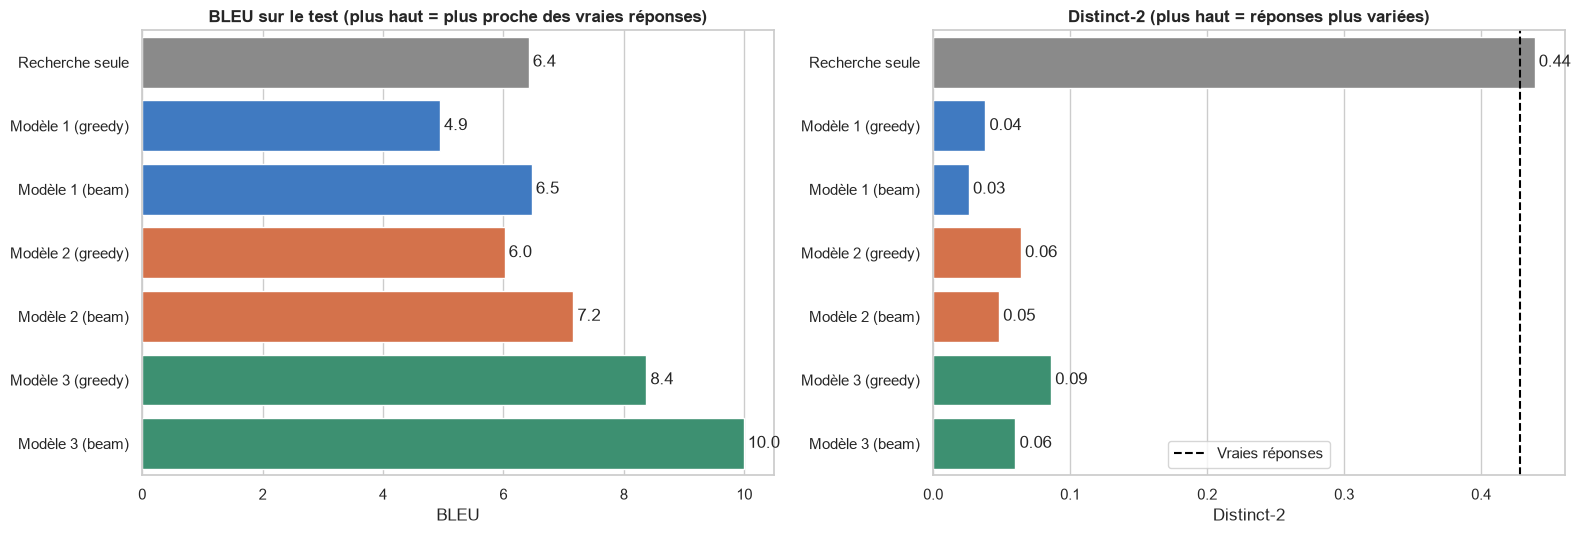

In [76]:
a_tracer = resultats.drop(index="Vraie réponse").reset_index().rename(columns={"index": "Système"})
palette = {s: ("#2a78d6" if "1" in s else "#eb6834" if "2" in s else "#2f9e74" if "3" in s else "#8a8a8a")
           for s in a_tracer["Système"]}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, mesure in zip(axes, ["BLEU", "Distinct-2"]):
    sns.barplot(data=a_tracer, y="Système", x=mesure, hue="Système", palette=palette,
                legend=False, ax=ax)
    for conteneur in ax.containers:
        ax.bar_label(conteneur, fmt="%.2f" if mesure == "Distinct-2" else "%.1f", padding=3)
    ax.set_ylabel("")
axes[0].set_title("BLEU sur le test (plus haut = plus proche des vraies réponses)", weight="bold")
axes[1].set_title("Distinct-2 (plus haut = réponses plus variées)", weight="bold")
axes[1].axvline(resultats.loc["Vraie réponse", "Distinct-2"], color="black", linestyle="--",
                label="Vraies réponses")
axes[1].legend()
plt.tight_layout()
plt.savefig("../reports/figures/comparaison_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :**

Le graphique résume le compromis entre ressemblance et diversité. À gauche, le BLEU augmente du
modèle 1 au modèle 3, et le beam search améliore chaque modèle : le modèle 3 avec beam search est
le seul système nettement au-dessus de la recherche seule. À droite, la recherche seule atteint la
diversité des vraies réponses, puisqu'elle renvoie des réponses écrites par des agents, alors que
les trois modèles restent très en dessous ; le greedy search y est, pour chaque modèle, plus varié
que le beam search. Le modèle 3 offre le meilleur compromis : à méthode de génération égale, il est à la fois le plus proche des vraies réponses et le plus varié des trois modèles.

## 12. Exemples de réponses réussies et d'échecs

Les mesures globales sont complétées par une analyse qualitative : un exemple où la réponse
attendue contient une information précise, les meilleures et les pires réponses du modèle 3, et
les réponses les plus répétées par chaque système.

### 12.1 Un message nécessitant une information précise

Le message ci-dessous (vu à la section 9) demande pourquoi un téléphone ne peut pas être acheté ;
la vraie réponse contient une information que les modèles 1 et 2 ne pouvaient pas connaître. On
compare les réponses des trois modèles, en affichant le cas retrouvé par la recherche.

In [77]:
def repondre(message, marque):
    """Cas retrouvé et réponses des 3 modèles (beam search) pour un message adressé à une marque."""
    cas, sim = rechercher(pd.DataFrame({"message": [message], "marque": [marque]}))
    reponse_cas = train["reponse"][cas[0]]
    print(f"Message ({marque}) : {message}")
    print(f"Cas similaire      : {train['message'][cas[0]]}  (similarité {sim[0]:.2f})")
    print(f"Réponse du cas     : {reponse_cas}")
    print(f"Modèle 1           : {generer_beam(modele1, message)}")
    print(f"Modèle 2           : {generer_beam(modele2, message)}")
    print(f"Modèle 3           : {generer_beam(modele3, message, reponse_cas)}")


redmi = val[val["message"].str.contains("redmi 4a")].iloc[0]
repondre(redmi["message"], redmi["marque"])
print(f"Vraie réponse      : {redmi['reponse']}")

100%|██████████| 1/1 [00:00<00:00,  4.38it/s]


Message (AmazonHelp) : hey amazon ! i am trying to book redmi 4a mobile . its not working . in both mobile and desktop . check it once
Cas similaire      : on my mobile or my pc desktop i am unable to open amazon site or even in mobile app  (similarité 0.41)
Réponse du cas     : what is the error you're getting mohsin when you try to open it ?
Modèle 1           : i'm sorry for the trouble ! please send us a dm with your email address so we can connect .
Modèle 2           : i'm sorry for the trouble ! please reach out to us here <url> so we can look into this for you .
Modèle 3           : i'm sorry for the trouble ! please reach out to us here <url> so we can look into this for you .
Vraie réponse      : currently redmi 4a is available on flash sale . please stay tuned to our website for next sale .


In [78]:
# Messages d'entraînement adressés à Amazon au sujet du Redmi
redmi_train = train[(train["marque"] == "AmazonHelp") & train["message"].str.contains("redmi")]
print(f"Messages d'entraînement sur le Redmi (AmazonHelp) : {len(redmi_train)}")
redmi_train[["message", "reponse"]].head(5)

Messages d'entraînement sur le Redmi (AmazonHelp) : 23


,message,reponse
660,"hi amazon , i was planning to buy honor redmi ...",i get your concern about the price fluctuation...
9867,i bought redmi note 4 but today while repairin...,that's highly unusual . kindly share your deta...
14560,shame on amazongreatindianfestival my phone st...,apologies for the trouble . please drop your d...
18641,how can i purchase redmi 4a 16 gb from your we...,"i m sorry about that , the mobile is available..."
19272,hey is there c0d available on redmi 4 2gb duri...,"cod depends on product , pincode , seller and ..."


**Interprétation :**

Sur cet exemple, la recherche ne retrouve pas un cas utile : le message retrouvé partage des mots avec le message du client (« mobile », présent deux fois dans le message, et « desktop »), mais il concerne un site inaccessible et non l’achat d’un téléphone. Sa réponse
ne contient donc pas l'information attendue, et le modèle 3 produit la même réponse générale que le
modèle 2 : il ne recopie pas un cas inadapté, mais ne peut pas non plus apporter l'information
manquante.

Pourtant, l’ensemble d’entraînement contient 23 messages adressés à Amazon au sujet du Redmi, dont un client qui demande comment acheter le Redmi 4A (« how can i purchase redmi 4a 16 gb… »), avec une réponse sur la disponibilité du téléphone. Ce cas n’est pas retenu : malgré l’IDF élevé de « redmi », le message retrouvé partage davantage de mots avec le message du client, et seul le cas le plus similaire est conservé. Cet exemple illustre la principale limite du modèle 3 : la qualité de ses réponses dépend de celle de la recherche, et la similarité TF-IDF additionne tous les mots en commun sans distinguer ceux qui décrivent vraiment le problème. Conserver plusieurs cas, utiliser une pondération de type BM25 ou une recherche fondée sur le sens (embeddings) seraient des améliorations naturelles.

### 12.2 Meilleures et pires réponses du modèle 3

Pour chaque message de l'échantillon de test, on calcule le BLEU de la réponse du modèle 3 (beam
search) au niveau de la phrase, puis on affiche les trois réponses les plus proches de la vraie
réponse et les trois plus éloignées.

In [79]:
from nltk.translate.bleu_score import sentence_bleu

lissage = SmoothingFunction().method1
reponses["BLEU modèle 3"] = [100 * sentence_bleu([r.split()], h.split(), smoothing_function=lissage)
                             for r, h in zip(reponses["Vraie réponse"], reponses["Modèle 3 (beam)"])]


def afficher(lignes):
    for _, ligne in lignes.iterrows():
        print(f"Message ({ligne['marque']}) : {ligne['message']}")
        print(f"Vraie réponse    : {ligne['Vraie réponse']}")
        print(f"Recherche seule  : {ligne['Recherche seule']}")
        print(f"Modèle 3 (beam)  : {ligne['Modèle 3 (beam)']}  (BLEU {ligne['BLEU modèle 3']:.1f})")
        print("-" * 100)


print("=== Les 3 meilleures réponses ===\n")
afficher(reponses.nlargest(3, "BLEU modèle 3"))
print("\n=== Les 3 pires réponses ===\n")
afficher(reponses.nsmallest(3, "BLEU modèle 3"))

=== Les 3 meilleures réponses ===

Message (DunkinDonuts) : i realize that stores get busy , but that's no excuse for cold food . my cold wrap was disgusting .
Vraie réponse    : oh no ! sry to hear this ! plz dm us so we can make this right !
Recherche seule  : oh no ! sry to hear this ! plz dm us so we can make this right !
Modèle 3 (beam)  : oh no ! sry to hear this ! plz dm us so we can make this right !  (BLEU 100.0)
----------------------------------------------------------------------------------------------------
Message (SpotifyCares) : i can't login to my account . everytime i do it just kicks me out .
Vraie réponse    : hi there ! can you dm us your account's email address or username ? we'll take a look backstage gt <url>
Recherche seule  : hey ! you can contact our artist team here <url> if you've reached out , dm us your email address and we'll chase it up k <url>
Modèle 3 (beam)  : hey there ! can you dm us your account's email address or username ? we'll take a look bac

**Interprétation :**

Les meilleures réponses du modèle 3 correspondent à des réponses types, qu'une marque utilise pour
de nombreux clients : pour Dunkin' Donuts, la réponse générée est identique à la vraie réponse et
au cas retrouvé. L'exemple de Spotify montre que le modèle ne se contente pas de recopier le cas :
le cas retrouvé portait sur un autre sujet, mais le modèle produit une réponse presque identique à
celle de l'agent, apprise à partir des nombreuses réponses de cette marque.

Les pires réponses concernent d'abord les réponses factuelles : pour une question sur le délai
d'apparition des miles (Virgin Atlantic), la vraie réponse donne un délai (« up to 72hrs ») ; le cas retrouvé en donnait un aussi, mais différent (« up to 21 days »), et le modèle demande une référence de réservation au lieu de répondre. Même exploitée, l’information du cas aurait été inexacte : la recherche retrouve un cas proche, pas nécessairement la bonne information. Elles concernent aussi des réponses très courtes et personnelles, qu'aucun modèle ne
peut reproduire et que le BLEU pénalise fortement : cette mesure ne compare qu'à une seule réponse
de référence.

### 12.3 Les réponses les plus répétées

Pour mesurer concrètement le manque de diversité, on compte, pour chaque système, combien de
réponses différentes il produit sur les 1 000 messages, et quelle part représente sa réponse la
plus fréquente.

In [80]:
repetitions = pd.DataFrame({
    "Réponses différentes (sur 1 000)": [reponses[s].nunique() for s in systemes],
    "% de la réponse la plus fréquente": [reponses[s].value_counts().iloc[0] / 10 for s in systemes],
}, index=systemes)
display(repetitions)

print("\n=== Les 3 réponses les plus fréquentes du modèle 1 (greedy) ===")
print(reponses["Modèle 1 (greedy)"].value_counts().head(3))

,Réponses différentes (sur 1 000),% de la réponse la plus fréquente
Vraie réponse,998,0.2
Recherche seule,992,0.2
Modèle 1 (greedy),330,5.1
Modèle 1 (beam),245,8.1
Modèle 2 (greedy),559,4.2
Modèle 2 (beam),374,6.8
Modèle 3 (greedy),712,2.5
Modèle 3 (beam),566,4.8



=== Les 3 réponses les plus fréquentes du modèle 1 (greedy) ===
Modèle 1 (greedy)
we'd like to help . please dm us your current ios version and we'll go from there . <url>                     51
hi there ! please send us a dm with your email address so we can connect .                                    47
hi there , i'm sorry to hear this . can you dm me your order number , address and email address ? thanks .    25
Name: count, dtype: int64


**Interprétation :**

Sur 1 000 messages, les agents écrivent 998 réponses différentes, alors que le modèle 1 n'en
produit que 245 avec le beam search, et donne la même réponse à 8,1 % des messages. En greedy, ses réponses les plus fréquentes sont des réponses types des marques les plus représentées (la version d'iOS
pour Apple, l'adresse email ou le numéro de commande en message privé) : faute de mieux, le modèle
se rabat sur les formules qu'il a vues le plus souvent. Le modèle 3 est nettement plus varié
(712 réponses différentes en greedy, 566 en beam search) : la réponse du cas similaire lui fournit
des éléments propres à chaque message. Le beam search réduit la diversité pour les trois modèles,
ce qui confirme le compromis observé à la section 11.

## 13. Synthèse

| Système | Perplexité (test) | BLEU (beam) | Distinct-2 (beam) |
|---|---|---|---|
| Modèle 1 : LSTM | 12,72 | 6,47 | 0,026 |
| Modèle 2 : LSTM + attention | 11,47 | 7,16 | 0,048 |
| Modèle 3 : LSTM + attention + cas similaire | **10,71** | **9,99** | **0,060** |
| Recherche seule (sans génération) | — | 6,42 | 0,439 |

Chaque ajout améliore le système : l'attention permet au décodeur de s'appuyer sur les mots
importants du message, et la réponse d'un cas similaire lui fournit un modèle de réponse propre à
la marque. Le modèle 3 obtient les meilleurs résultats des trois modèles sur toutes les mesures, et dépasse
nettement la simple recherche du cas le plus proche. Les trois modèles ont appris le style et les
procédures des marques, mais leurs réponses restent beaucoup moins variées que celles des agents,
et ils ne peuvent pas fournir une information factuelle absente de leurs données ou mal retrouvée
par la recherche. Les principales améliorations possibles sont une recherche fondée sur le sens
plutôt que sur les mots, l'utilisation de plusieurs cas similaires, et une génération favorisant
la diversité.

## 14. Export pour l'application

On enregistre tout ce dont l'application Streamlit a besoin : le vocabulaire, l'IDF, la mémoire
des cas (messages, réponses et marques de l'entraînement), la matrice TF-IDF et les paramètres des
trois modèles.

In [81]:
DOSSIER_APP = "../app/ressources"
os.makedirs(DOSSIER_APP, exist_ok=True)

torch.save({
    "id2mot": id2mot,
    "idf": idf,
    "config": {"MAX_LEN_MESSAGE": MAX_LEN_MESSAGE, "MAX_LEN_REPONSE": MAX_LEN_REPONSE,
               "TAILLE_EMBEDDING": TAILLE_EMBEDDING, "TAILLE_CACHEE": TAILLE_CACHEE},
    "memoire": train[["message", "reponse", "marque"]].to_dict("list"),
    "M_train": M_train.coalesce(),
    "numeros_marques": numeros_marques,
}, f"{DOSSIER_APP}/ressources.pt")

for i, modele in enumerate([modele1, modele2, modele3], start=1):
    torch.save(modele.state_dict(), f"{DOSSIER_APP}/modele{i}.pt")

for fichier in sorted(os.listdir(DOSSIER_APP)):
    print(f"{fichier:16s} {os.path.getsize(f'{DOSSIER_APP}/{fichier}') / 1e6:6.1f} Mo")

modele1.pt         23.7 Mo
modele2.pt         24.5 Mo
modele3.pt         24.5 Mo
ressources.pt      74.8 Mo


**Interprétation :**

Les fichiers des modèles pèsent 23,7 Mo (modèle 1) et 24,5 Mo (modèles 2 et 3), ce qui correspond à leur nombre de paramètres (4 octets par paramètre). Le fichier des ressources (74,8 Mo) contient surtout la mémoire des cas et la matrice TF-IDF. L’application peut ainsi charger les trois modèles entraînés et retrouver un cas similaire sans refaire aucun calcul d’entraînement.